# Чекпойнт №2. Разведочный анализ данных (EDA)

* **Проект:** предсказание котировок криптовалют (ML-трек)
* **Команда:** Кузнецов Дмитрий, Халидов Асхаб
* **Куратор:** Качкин Дмитрий

## Паспорт данных

| | |
|---|---|
| **Источник** | публичный архив биржи Binance, https://data.binance.vision (без ключей API) |
| **Основной инструмент** | BTCUSDT: спотовый рынок и бессрочный фьючерс USDⓈ-M |
| **Дополнительно** | ETHUSDT и SOLUSDT, спот (для сравнения активов) |
| **Период** | 01.01.2020 – 31.10.2026 (с января 2020 в архиве есть и спот, и фьючерсы) |
| **Шаг свечей** | 1 час, время в UTC |
| **Как получены** | скрипт `src/download_data.py`, результат лежит в `data/raw/` |

**Колонки свечи** (одинаковые для спота и фьючерса):

* `open`, `high`, `low`, `close` — цена открытия, максимум, минимум и цена закрытия за час, в USDT;
* `volume` — объём торгов в BTC;
* `quote_volume` — тот же объём в USDT (оборот);
* `trades` — число сделок;
* `taker_buy_volume`, `taker_buy_quote_volume` — объём сделок, в которых инициатором был покупатель (он «взял» заявку продавца из стакана).

## План

1. Загрузка данных и первый взгляд
2. Качество данных: дубли, пропуски, ошибочные значения, корректность OHLC
3. Целевая переменная и признаки, основные статистики
4. Графики рядов на общей оси времени
5. Выбросы и скачки цены
6. Распределение доходностей
7. Волатильность
8. Автокорреляция (ACF, PACF)
9. Стационарность (ADF, KPSS)
10. Сезонность: час суток, день недели, месяц
11. Связь признаков с целевой переменной
12. Связь с объёмом фьючерсов
13. Сравнение BTC, ETH и SOL
14. Очищенный датасет
15. Выводы

# 1. Загрузка данных и первый взгляд

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from scipy import stats

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')
np.random.seed(42)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
# большие числа показываем с двумя знаками, маленькие — с четырьмя
pd.set_option('display.float_format', lambda x: f'{x:,.2f}' if abs(x) >= 100 else f'{x:.4f}')

In [2]:
# Единое оформление графиков
BLUE, ORANGE, AQUA, RED, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#52514e'

sns.set_theme(style='whitegrid', palette=[BLUE, ORANGE, AQUA])
plt.rcParams.update({
    'figure.dpi': 90,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'grid.color': '#e6e5e0',
    'grid.linewidth': 0.6,
    'lines.linewidth': 1.2,
})

Данные скачаны заранее скриптом `src/download_data.py` и лежат в папке `data/raw/`. Если ноутбук открыт без этой папки (например, в Colab), файлы читаются напрямую из репозитория на GitHub.

In [3]:
DATA_DIR = 'data/raw'
GITHUB_RAW = 'https://raw.githubusercontent.com/kuz9d/crypto-sentiment-forecast/main/data/raw'


def load_klines(market, symbol):
    # Читает часовые свечи: market — 'spot' или 'futures', symbol — тикер
    name = f'{market}_{symbol}_1h.csv.gz'
    path = os.path.join(DATA_DIR, name)
    if not os.path.exists(path):
        path = f'{GITHUB_RAW}/{name}'
    return pd.read_csv(path, parse_dates=['open_time'])


spot = load_klines('spot', 'BTCUSDT')     # BTC, спотовый рынок
fut = load_klines('futures', 'BTCUSDT')   # BTC, бессрочный фьючерс
eth = load_klines('spot', 'ETHUSDT')
sol = load_klines('spot', 'SOLUSDT')

print('BTC спот:   ', spot.shape)
print('BTC фьючерс:', fut.shape)

BTC спот:    (59873, 10)
BTC фьючерс: (59880, 10)


Как выглядят данные?

In [4]:
spot.head()

,open_time,open,high,low,close,volume,quote_volume,trades,taker_buy_volume,taker_buy_quote_volume
0,2020-01-01 00:00:00,"7,195.24","7,196.25","7,175.46","7,177.02",511.81,"3,675,856.58",7640,226.15,"1,624,289.19"
1,2020-01-01 01:00:00,"7,176.47","7,230.00","7,175.71","7,216.27",883.05,"6,365,952.54",9033,570.72,"4,114,804.05"
2,2020-01-01 02:00:00,"7,215.52","7,244.87","7,211.41","7,242.85",655.16,"4,736,719.39",7466,357.18,"2,582,513.83"
3,2020-01-01 03:00:00,"7,242.66","7,245.00","7,220.00","7,225.01",783.72,"5,667,367.29",8337,394.81,"2,854,987.36"
4,2020-01-01 04:00:00,"7,225.00","7,230.00","7,215.03","7,217.27",467.81,"3,379,093.85",5896,243.51,"1,759,053.45"


In [5]:
fut.head()

,open_time,open,high,low,close,volume,quote_volume,trades,taker_buy_volume,taker_buy_quote_volume
0,2020-01-01 00:00:00,"7,189.43","7,190.52","7,170.15","7,171.55","2,449.05","17,576,424.44",3688,996.20,"7,149,370.76"
1,2020-01-01 01:00:00,"7,171.43","7,225.00","7,171.10","7,210.24","3,865.04","27,838,046.01",6635,"2,340.88","16,860,294.05"
2,2020-01-01 02:00:00,"7,210.38","7,239.30","7,206.46","7,237.99","3,228.36","23,324,810.41",5120,"1,774.14","12,818,470.64"
3,2020-01-01 03:00:00,"7,237.41","7,239.74","7,215.00","7,221.65","2,513.31","18,161,821.86",4143,"1,245.07","8,996,218.69"
4,2020-01-01 04:00:00,"7,221.80","7,225.41","7,211.22","7,213.86","1,176.67","8,493,630.87",1966,586.86,"4,236,084.26"


In [6]:
spot.info()

<class 'pandas.DataFrame'>
RangeIndex: 59873 entries, 0 to 59872
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   open_time               59873 non-null  datetime64[us]
 1   open                    59873 non-null  float64       
 2   high                    59873 non-null  float64       
 3   low                     59873 non-null  float64       
 4   close                   59873 non-null  float64       
 5   volume                  59873 non-null  float64       
 6   quote_volume            59873 non-null  float64       
 7   trades                  59873 non-null  int64         
 8   taker_buy_volume        59873 non-null  float64       
 9   taker_buy_quote_volume  59873 non-null  float64       
dtypes: datetime64[us](1), float64(8), int64(1)
memory usage: 4.6 MB


Все колонки числовые, время распозналось как дата, пустых ячеек (`NaN`) в файлах нет. Но для временного ряда этого мало: пропуск может выглядеть не как `NaN`, а как **отсутствующая строка**. Проверим это в следующем разделе.

# 2. Качество данных

Порядок такой же, как на лекции: сначала ищем проблемы (дубли, пропуски, ошибочные значения), потом их обрабатываем.

## 2.1. Дубли и пропущенные свечи

При шаге в 1 час с 01.01.2020 по 31.10.2026 должно быть ровно 59 904 свечи. Построим «идеальную» сетку времени и сравним с ней каждый ряд.

In [7]:
full_index = pd.date_range('2020-01-01 00:00', '2026-10-31 23:00', freq='h')
print('Свечей в полном периоде:', len(full_index))

raw = {'BTC спот': spot, 'BTC фьючерс': fut, 'ETH спот': eth, 'SOL спот': sol}

rows = {}
for name, d in raw.items():
    expected = full_index[full_index >= d['open_time'].min()]   # SOL торгуется не с начала периода
    n_missing = len(expected.difference(d['open_time']))
    rows[name] = {
        'первая свеча': d['open_time'].min(),
        'последняя свеча': d['open_time'].max(),
        'строк в файле': len(d),
        'должно быть': len(expected),
        'пропущено свечей': n_missing,
        'доля пропусков, %': round(n_missing / len(expected) * 100, 3),
        'дублей по времени': d['open_time'].duplicated().sum(),
        'полных дублей строк': d.duplicated().sum(),
        'NaN в ячейках': d.isna().sum().sum(),
        'время по возрастанию': d['open_time'].is_monotonic_increasing,
    }

pd.DataFrame(rows).T

Свечей в полном периоде: 59904


,первая свеча,последняя свеча,строк в файле,должно быть,пропущено свечей,"доля пропусков, %",дублей по времени,полных дублей строк,NaN в ячейках,время по возрастанию
BTC спот,2020-01-01 00:00:00,2026-10-31 23:00:00,59873,59904,31,0.0520,0,0,0,True
BTC фьючерс,2020-01-01 00:00:00,2026-10-31 23:00:00,59880,59904,24,0.0400,0,0,0,True
ETH спот,2020-01-01 00:00:00,2026-10-31 23:00:00,59873,59904,31,0.0520,0,0,0,True
SOL спот,2020-08-11 06:00:00,2026-10-31 23:00:00,54527,54546,19,0.0350,0,0,0,True


Что видно:

* дублей нет, время идёт по возрастанию, `NaN` в файлах нет;
* но не хватает свечей: 31 час в споте BTC (0.052%), 24 часа во фьючерсе (0.040%), 31 в ETH и 19 в SOL;
* SOL торгуется на Binance с 11.08.2020, поэтому его ряд короче.

In [8]:
def find_gaps(d):
    # Возвращает таблицу непрерывных пропусков: начало, конец, длина в часах
    expected = full_index[full_index >= d['open_time'].min()]
    missing = pd.Series(expected.difference(d['open_time']))
    block = (missing.diff() != pd.Timedelta(hours=1)).cumsum()   # новый номер у каждого разрыва
    gaps = missing.groupby(block).agg(['min', 'max', 'count']).reset_index(drop=True)
    gaps.columns = ['начало', 'конец', 'часов']
    return gaps


gaps_spot = find_gaps(spot)
gaps_fut = find_gaps(fut)

print('Пропуски во фьючерсе:')
display(gaps_fut)
print('Пропуски в споте:')
gaps_spot

Пропуски во фьючерсе:


,начало,конец,часов
0,2026-10-28,2026-10-28 23:00:00,24


Пропуски в споте:


,начало,конец,часов
0,2020-02-09 02:00:00,2020-02-09 02:00:00,1
1,2020-02-19 12:00:00,2020-02-19 16:00:00,5
2,2020-03-04 10:00:00,2020-03-04 10:00:00,1
3,2020-04-25 02:00:00,2020-04-25 03:00:00,2
4,2020-06-28 02:00:00,2020-06-28 04:00:00,3
5,2020-11-30 06:00:00,2020-11-30 06:00:00,1
6,2020-12-21 15:00:00,2020-12-21 17:00:00,3
7,2020-12-25 02:00:00,2020-12-25 02:00:00,1
8,2021-02-11 04:00:00,2021-02-11 04:00:00,1
9,2021-03-06 02:00:00,2021-03-06 02:00:00,1


## 2.2. Что означают пропуски? Гипотезы и проверка

**Гипотеза 1 (спот).** Пропущенные часы — это остановки торгов на спотовом рынке Binance (технические работы или сбои). В эти часы сделок не было, поэтому свечи нет.

Как это проверить:

* если биржа останавливала спот целиком, то те же самые часы должны отсутствовать и у других пар (ETH, SOL);
* фьючерсный рынок — это отдельная система, он в эти часы мог работать;
* плановые работы обычно назначают на одно и то же время суток;
* прямо перед остановкой и сразу после неё объём торгов должен быть необычным.

In [9]:
missing_btc = set(full_index.difference(spot['open_time']))
missing_eth = set(full_index.difference(eth['open_time']))

sol_start = sol['open_time'].min()
missing_sol = set(full_index[full_index >= sol_start].difference(sol['open_time']))
missing_btc_after_sol = {t for t in missing_btc if t >= sol_start}

print('BTC и ETH: пропущены одни и те же часы —', missing_btc == missing_eth)
print('BTC и SOL (с момента листинга SOL): одни и те же часы —', missing_btc_after_sol == missing_sol)

fut_in_gaps = fut[fut['open_time'].isin(missing_btc)]
print(f'\nФьючерсных свечей в часы, когда спот «молчал»: {len(fut_in_gaps)} из {len(missing_btc)}')
print('Сделок на фьючерсе в эти часы (медиана за час):', int(fut_in_gaps['trades'].median()))

print('\nВ какой час (UTC) начинались пропуски:')
print(gaps_spot['начало'].dt.hour.value_counts().sort_index().to_string())

BTC и ETH: пропущены одни и те же часы — True
BTC и SOL (с момента листинга SOL): одни и те же часы — True



Фьючерсных свечей в часы, когда спот «молчал»: 31 из 31
Сделок на фьючерсе в эти часы (медиана за час): 71799

В какой час (UTC) начинались пропуски:
начало
2     7
4     1
5     1
6     1
7     1
10    1
12    1
13    1
15    1


In [10]:
# Объём в последней свече перед пропуском и в первой после него —
# в процентах от обычного (медиана за предыдущие сутки)
s = spot.set_index('open_time')
hour = pd.Timedelta(hours=1)

before, after = [], []
for start, end in zip(gaps_spot['начало'], gaps_spot['конец']):
    usual = s.loc[start - 25 * hour: start - 2 * hour, 'volume'].median()
    before.append(s.loc[start - hour, 'volume'] / usual * 100)
    after.append(s.loc[end + hour, 'volume'] / usual * 100)

gaps_check = gaps_spot.copy()
gaps_check['объём перед пропуском, % от обычного'] = np.round(before).astype(int)
gaps_check['объём после пропуска, % от обычного'] = np.round(after).astype(int)
display(gaps_check)

print('Пропусков, перед которыми объём был ниже 65% обычного:',
      (gaps_check['объём перед пропуском, % от обычного'] < 65).sum(), 'из', len(gaps_check))

,начало,конец,часов,"объём перед пропуском, % от обычного","объём после пропуска, % от обычного"
0,2020-02-09 02:00:00,2020-02-09 02:00:00,1,60,307
1,2020-02-19 12:00:00,2020-02-19 16:00:00,5,20,193
2,2020-03-04 10:00:00,2020-03-04 10:00:00,1,14,98
3,2020-04-25 02:00:00,2020-04-25 03:00:00,2,55,36
4,2020-06-28 02:00:00,2020-06-28 04:00:00,3,94,45
5,2020-11-30 06:00:00,2020-11-30 06:00:00,1,76,144
6,2020-12-21 15:00:00,2020-12-21 17:00:00,3,0,144
7,2020-12-25 02:00:00,2020-12-25 02:00:00,1,57,57
8,2021-02-11 04:00:00,2021-02-11 04:00:00,1,0,69
9,2021-03-06 02:00:00,2021-03-06 02:00:00,1,49,31


Пропусков, перед которыми объём был ниже 65% обычного: 11 из 15


Что видно:

* 15 пропусков длиной от 1 до 5 часов, 14 из них в 2020–2021 годах, после марта 2023 пропусков нет;
* у BTC, ETH и SOL пропущены одни и те же часы, то есть дело в бирже, а не в конкретной паре;
* фьючерс в эти часы торговался: свечи есть за все 31 час;
* 7 пропусков из 15 начинаются в 02:00 UTC, это похоже на плановые работы;
* в 11 случаях из 15 объём перед пропуском ниже 65% обычного.

Гипотеза подтверждается: пропуски в споте — это остановки спотовых торгов на Binance.

**Гипотеза 2 (фьючерс).** Во фьючерсном ряду пропущены ровно одни сутки, 28.10.2026. Целый календарный день похож не на остановку торгов, а на **дефект архива**: файл за этот день не попал в выгрузку.

Проверка: если рынок в этот день работал, то спот должен торговаться как обычно, а цена фьючерса до и после пропуска должна отличаться примерно на столько же, на сколько изменилась цена спота.

In [11]:
t0, t1 = gaps_fut.loc[0, 'начало'], gaps_fut.loc[0, 'конец']
f = fut.set_index('open_time')

spot_day = s.loc[t0:t1]
usual_day_volume = s.loc[t0 - 30 * 24 * hour: t0 - hour, 'volume'].resample('D').sum().median()

print(f'Спотовых свечей за {t0:%d.%m.%Y}: {len(spot_day)} из 24')
print(f'Объём спота за этот день: {spot_day["volume"].sum() / usual_day_volume * 100:.0f}% от обычного дневного')

spot_move = s.loc[t1 + hour, 'open'] / s.loc[t0 - hour, 'close'] - 1
fut_move = f.loc[t1 + hour, 'open'] / f.loc[t0 - hour, 'close'] - 1
print(f'Изменение цены за время пропуска: спот {spot_move:+.2%}, фьючерс {fut_move:+.2%}')

Спотовых свечей за 28.10.2026: 24 из 24
Объём спота за этот день: 95% от обычного дневного
Изменение цены за время пропуска: спот +0.54%, фьючерс +0.54%


28.10.2026 спот торговался все 24 часа с обычным объёмом, а цена фьючерса за время пропуска изменилась так же, как цена спота (+0.54%). Значит, торги шли, но данных нет в архиве. Это дефект выгрузки, а не остановка торгов.

## 2.3. Ошибочные значения и корректность OHLC

Ошибочные значения — это значения, которые **невозможны** по смыслу данных. Для свечей правила такие:

* цены строго больше нуля, объёмы и число сделок не отрицательные;
* `high` — максимум за час, значит он не меньше `open`, `close` и `low`;
* `low` — минимум за час, значит он не больше `open`, `close` и `high`;
* объём покупок тейкеров — часть общего объёма, он не может быть больше него;
* средняя цена сделок за час (`quote_volume / volume`) должна лежать между `low` и `high`;
* если объём больше нуля, то и сделок больше нуля.

Отдельно посчитаем свечи с нулевым объёмом и свечи без движения цены (`high = low`): это не обязательно ошибка, но на них стоит посмотреть.

In [12]:
def check_ohlcv(d):
    # Считает число строк, нарушающих каждое правило
    vwap = d['quote_volume'] / d['volume']       # средняя цена сделок за час
    eps = 1e-9                                   # допуск на округление
    return pd.Series({
        'цена ≤ 0': (d[['open', 'high', 'low', 'close']] <= 0).any(axis=1).sum(),
        'объём или сделки < 0': (d[['volume', 'quote_volume', 'trades', 'taker_buy_volume']] < 0).any(axis=1).sum(),
        'high меньше open / close / low': (d['high'] < d[['open', 'close', 'low']].max(axis=1)).sum(),
        'low больше open / close / high': (d['low'] > d[['open', 'close', 'high']].min(axis=1)).sum(),
        'покупки тейкеров больше объёма': (d['taker_buy_volume'] > d['volume'] * (1 + eps)).sum(),
        'средняя цена вне [low, high]': ((vwap < d['low'] * (1 - eps)) | (vwap > d['high'] * (1 + eps))).sum(),
        'объём > 0 при нуле сделок': ((d['volume'] > 0) & (d['trades'] == 0)).sum(),
        'нулевой объём': (d['volume'] == 0).sum(),
        'свеча без движения (high = low)': (d['high'] == d['low']).sum(),
    })


pd.DataFrame({name: check_ohlcv(d) for name, d in raw.items()})

,BTC спот,BTC фьючерс,ETH спот,SOL спот
цена ≤ 0,0,0,0,0
объём или сделки < 0,0,0,0,0
high меньше open / close / low,0,0,0,0
low больше open / close / high,0,0,0,0
покупки тейкеров больше объёма,0,0,0,0
"средняя цена вне [low, high]",0,0,0,0
объём > 0 при нуле сделок,0,0,0,0
нулевой объём,3,1,3,3
свеча без движения (high = low),3,1,3,3


In [13]:
print('Спот: свечи с нулевым объёмом')
display(spot[spot['volume'] == 0][['open_time', 'open', 'high', 'low', 'close', 'volume', 'trades']])
print('Фьючерс: свечи с нулевым объёмом')
fut[fut['volume'] == 0][['open_time', 'open', 'high', 'low', 'close', 'volume', 'trades']]

Спот: свечи с нулевым объёмом


,open_time,open,high,low,close,volume,trades
8521,2020-12-21 14:00:00,"22,646.53","22,646.53","22,646.53","22,646.53",0.0000,0
9754,2021-02-11 03:00:00,"44,582.07","44,582.07","44,582.07","44,582.07",0.0000,0
28254,2023-03-24 12:00:00,"28,080.00","28,080.00","28,080.00","28,080.00",0.0000,0


Фьючерс: свечи с нулевым объёмом


,open_time,open,high,low,close,volume,trades
42308,2024-10-28 20:00:00,"69,566.10","69,566.10","69,566.10","69,566.10",0.0000,0


Ещё одна проверка на «склейку» свечей: цена открытия часа должна почти совпадать с ценой закрытия предыдущего часа. Большой разрыв означал бы потерянные данные или ошибку в ценах.

In [14]:
for name, d in [('спот', spot), ('фьючерс', fut)]:
    step = d['open_time'].diff()
    jump = (d['open'] / d['close'].shift() - 1).abs()
    jump_no_gap = jump[step == pd.Timedelta(hours=1)]     # только соседние часы
    print(f'{name}: разрыв open против предыдущего close — медиана {jump_no_gap.median():.4%}, '
          f'максимум {jump_no_gap.max():.3%}, больше 0.5%: {(jump_no_gap > 0.005).sum()} шт.')

спот: разрыв open против предыдущего close — медиана 0.0000%, максимум 0.190%, больше 0.5%: 0 шт.
фьючерс: разрыв open против предыдущего close — медиана 0.0000%, максимум 0.289%, больше 0.5%: 0 шт.


Что видно:

* ни одно правило не нарушено ни в одном ряду;
* свечи состыкованы: цена открытия отличается от предыдущего закрытия максимум на 0.19% в споте и 0.29% во фьючерсе;
* нулевой объём у 3 свечей в споте и 1 во фьючерсе, все они без сделок и без движения цены;
* три спотовые свечи с нулевым объёмом стоят прямо перед пропусками, то есть это те же остановки торгов.

Ошибочных значений нет. Обрабатывать нужно только пропуски.

## 2.4. Обработка пропусков

Соберём спот и фьючерс в одну таблицу на общей сетке времени. Отсутствующие свечи превратятся в строки с `NaN`, и мы увидим «разреженность» датасета по каждому признаку, как на лекции.

In [15]:
spot_i = spot.set_index('open_time').reindex(full_index)
fut_i = fut.set_index('open_time').add_prefix('fut_').reindex(full_index)

df = spot_i.join(fut_i)
df.index.name = 'time'

missing = df.isna().sum()
display(pd.DataFrame({
    'пропусков': missing,
    'доля, %': (missing / len(df) * 100).round(3),
}))
print(f'Всего пустых ячеек: {df.isna().sum().sum()} из {df.size} ({df.isna().sum().sum() / df.size:.3%})')

,пропусков,"доля, %"
open,31,0.0520
high,31,0.0520
low,31,0.0520
close,31,0.0520
volume,31,0.0520
quote_volume,31,0.0520
trades,31,0.0520
taker_buy_volume,31,0.0520
taker_buy_quote_volume,31,0.0520
fut_open,24,0.0400


Всего пустых ячеек: 495 из 1078272 (0.046%)


**Решение по пропускам.**

**Спот (31 час, остановки торгов).** В эти часы сделок не было, значит:

* объём и число сделок равны нулю — это не оценка, а факт;
* цена не менялась, то есть `open = high = low = close =` последняя цена перед остановкой.

Биржа сама записывает часы без сделок именно так (три такие свечи мы нашли выше). Среднее или медиана здесь не подходят: они подставили бы объём, которого не было, и цену из другого времени. Строки помечаем флагом `spot_halt`, чтобы при желании исключать их из анализа.

**Фьючерс (24 часа, дефект архива).** Торги шли, но данных у нас нет. Придумывать объём и цену мы не будем: оставляем `NaN` и помечаем строки флагом `fut_missing`. Это 0.04% ряда, в расчётах по фьючерсу эти часы просто не участвуют. К следующему чекпойнту попробуем дозагрузить этот день через API биржи.

In [16]:
spot_missing = df['close'].isna()            # свечи нет в архиве
df['fut_missing'] = df['fut_close'].isna()   # час, за который нет данных по фьючерсу

price_cols = ['open', 'high', 'low', 'close']
flow_cols = ['volume', 'quote_volume', 'trades', 'taker_buy_volume', 'taker_buy_quote_volume']

last_close = df['close'].ffill()             # последняя известная цена
for col in price_cols:
    df[col] = df[col].fillna(last_close)
df[flow_cols] = df[flow_cols].fillna(0)

# час без торгов на споте: свечи не было вовсе или биржа записала её с нулевым объёмом
df['spot_halt'] = df['volume'] == 0

print(f"Часов без торгов на споте: {df['spot_halt'].sum()} ({spot_missing.sum()} отсутствующих свечей + {(df['spot_halt'] & ~spot_missing).sum()} с нулевым объёмом)")
print('Часов без данных по фьючерсу:', df['fut_missing'].sum())
print('Пропусков в спотовых колонках после обработки:', df[price_cols + flow_cols].isna().sum().sum())
df.shape

Часов без торгов на споте: 34 (31 отсутствующих свечей + 3 с нулевым объёмом)
Часов без данных по фьючерсу: 24
Пропусков в спотовых колонках после обработки: 0


(59904, 20)

# 3. Целевая переменная и признаки

## 3.1. Целевая переменная

Предсказывать саму цену неудобно: она растёт в десятки раз за период, и «ошибка в 100 долларов» в 2020 и в 2026 году значит разное. Поэтому работаем с **логарифмической доходностью**:

$$r_t = \ln\frac{close_t}{close_{t-1}}$$

Для небольших изменений это почти то же самое, что процентное изменение цены, но лог-доходности удобно складывать: доходность за сутки равна сумме 24 часовых.

**Целевая переменная** (`target`) — лог-доходность **следующего** часа, $r_{t+1}$. Дополнительно смотрим на два родственных варианта:

* `target_abs` $= |r_{t+1}|$ — размер движения в следующем часе (без знака);
* `target_dir` — направление: «рост» или «не рост».

Все признаки ниже считаются только по данным, известным к концу часа $t$. Иначе модель «подглядывала» бы в будущее.

In [17]:
df['ret'] = np.log(df['close']).diff()        # доходность текущего часа
df['target'] = df['ret'].shift(-1)            # доходность следующего часа
df['target_abs'] = df['target'].abs()
df['target_dir'] = (df['target'] > 0).map({True: 'рост', False: 'не рост'}).where(df['target'].notna())

df[['close', 'ret', 'target', 'target_abs', 'target_dir']].head()

,close,ret,target,target_abs,target_dir
time,,,,,
2020-01-01 00:00:00,"7,177.02",NaN,0.0055,0.0055,рост
2020-01-01 01:00:00,"7,216.27",0.0055,0.0037,0.0037,рост
2020-01-01 02:00:00,"7,242.85",0.0037,-0.0025,0.0025,не рост
2020-01-01 03:00:00,"7,225.01",-0.0025,-0.0011,0.0011,не рост
2020-01-01 04:00:00,"7,217.27",-0.0011,0.0010,0.0010,рост


## 3.2. Признаки

| Признак | Что означает |
|---|---|
| `ret` | доходность текущего часа |
| `ret_24h` | доходность за последние 24 часа |
| `range` | размах свечи, $\ln(high/low)$ |
| `vol_24h` | волатильность: стандартное отклонение доходностей за 24 часа |
| `log_volume`, `log_fut_volume` | логарифм оборота в USDT на споте и на фьючерсе |
| `volume_rel`, `fut_volume_rel` | оборот относительно обычного (медиана за 7 дней) |
| `fut_spot_ratio` | во сколько раз оборот фьючерса больше оборота спота |
| `basis_bp` | базис: на сколько цена фьючерса выше цены спота, в базисных пунктах (1 б.п. = 0.01%) |
| `taker_buy_share`, `fut_taker_buy_share` | доля объёма, где инициатором был покупатель |

Категориальные признаки строим из времени: час (`hour`), день недели (`weekday`), торговая сессия (`session`, условное деление суток на три части), выходной (`is_weekend`), год (`year`).

In [18]:
df['ret_24h'] = df['ret'].rolling(24).sum()
df['range'] = np.log(df['high'] / df['low'])
df['vol_24h'] = df['ret'].rolling(24).std()

# деление на ноль и логарифм нуля не определены, поэтому нулевые объёмы заменяем на NaN
spot_turnover = df['quote_volume'].where(df['quote_volume'] > 0)
fut_turnover = df['fut_quote_volume'].where(df['fut_quote_volume'] > 0)

df['log_volume'] = np.log(spot_turnover)
df['log_fut_volume'] = np.log(fut_turnover)
df['volume_rel'] = df['quote_volume'] / df['quote_volume'].rolling(168).median()
df['fut_volume_rel'] = df['fut_quote_volume'] / df['fut_quote_volume'].rolling(168).median()
df['fut_spot_ratio'] = fut_turnover / spot_turnover

# в часы остановки спота его цена «застыла», базис там не имеет смысла
df['basis_bp'] = ((df['fut_close'] / df['close'] - 1) * 10_000).where(~df['spot_halt'])

df['taker_buy_share'] = df['taker_buy_volume'] / df['volume'].where(df['volume'] > 0)
df['fut_taker_buy_share'] = df['fut_taker_buy_volume'] / df['fut_volume'].where(df['fut_volume'] > 0)

# календарные (категориальные) признаки
WEEKDAYS = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
df['hour'] = df.index.hour
df['weekday'] = pd.Categorical.from_codes(df.index.dayofweek, categories=WEEKDAYS, ordered=True)
df['session'] = pd.cut(df['hour'], bins=[-1, 7, 15, 23],
                       labels=['Азия (00–08 UTC)', 'Европа (08–16 UTC)', 'Америка (16–24 UTC)'])
df['is_weekend'] = df.index.dayofweek >= 5
df['year'] = df.index.year

feature_cols = ['ret', 'ret_24h', 'range', 'vol_24h', 'log_volume', 'log_fut_volume',
                'volume_rel', 'fut_volume_rel', 'fut_spot_ratio', 'basis_bp',
                'taker_buy_share', 'fut_taker_buy_share']

print('Размер таблицы:', df.shape)

Размер таблицы: (59904, 40)


## 3.3. Основные статистики

`describe(include='all')` показывает статистики и для числовых, и для категориальных признаков: для числовых — среднее, разброс и квантили, для категориальных — число уникальных значений (`unique`), самое частое значение (`top`) и его частоту (`freq`).

In [19]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
open,"59,904.00",NaN,NaN,NaN,"50,433.62","30,888.53","4,131.23","24,201.18","44,637.51","69,812.85","126,011.18"
high,"59,904.00",NaN,NaN,NaN,"50,623.47","30,971.24","4,610.00","24,331.89","44,881.88","70,094.01","126,199.63"
low,"59,904.00",NaN,NaN,NaN,"50,235.27","30,803.08","3,782.13","24,081.23","44,364.03","69,539.65","125,252.74"
close,"59,904.00",NaN,NaN,NaN,"50,434.80","30,888.22","4,130.64","24,201.69","44,639.69","69,814.54","126,011.18"
volume,"59,904.00",NaN,NaN,NaN,"2,794.51","4,249.62",0.0000,705.39,"1,428.23","2,989.43","137,207.19"
quote_volume,"59,904.00",NaN,NaN,NaN,"93,091,471.69","108,006,739.80",0.0000,"30,546,480.53","59,318,460.82","115,057,789.76","3,005,633,669.26"
trades,"59,904.00",NaN,NaN,NaN,"109,954.77","120,021.79",0.0000,"36,666.00","67,693.00","136,012.00","3,520,247.00"
taker_buy_volume,"59,904.00",NaN,NaN,NaN,"1,379.76","2,118.82",0.0000,340.29,699.65,"1,475.05","68,611.45"
taker_buy_quote_volume,"59,904.00",NaN,NaN,NaN,"45,898,417.40","53,900,389.18",0.0000,"14,621,332.78","28,848,367.29","56,950,767.36","1,502,976,679.73"
fut_open,"59,880.00",NaN,NaN,NaN,"50,412.19","30,877.29","4,062.95","24,180.23","44,607.04","69,781.02","125,986.10"


Что видно:

* масштабы признаков очень разные: цена от 4 до 126 тысяч, обороты до миллиардов, доли от 0 до 1. Для линейных моделей понадобится масштабирование;
* средняя часовая доходность 0.004% при стандартном отклонении 0.65%: сигнал намного меньше шума;
* `count` меньше 59 904 там, где значение нельзя посчитать: нет данных фьючерса, начало ряда для скользящих окон, часы без торгов;
* у `fut_spot_ratio` максимум 1 330 при медиане 6.6, это выброс, вернёмся к нему в разделе 5.

**Баланс классов.** Если решать задачу как классификацию («рост» или «не рост»), важно знать долю каждого класса.

In [20]:
print(df['target_dir'].value_counts(normalize=True).round(4).to_string())
print(f"\nЧасов с нулевой доходностью: {(df['target'] == 0).sum()}")

target_dir
рост      0.5067
не рост   0.4933

Часов с нулевой доходностью: 37


Классы почти равны: рост в 50.7% часов. Модель, которая всегда отвечает «рост», даёт accuracy 50.7%, с этим числом и будем сравнивать.

# 4. Графики рядов на общей оси времени

Цена показана в логарифмической шкале: так одинаковое процентное изменение выглядит одинаково и в 2020, и в 2026 году. Объёмы для читаемости просуммированы по дням и показаны в одинаковом масштабе, чтобы спот и фьючерс можно было сравнивать на глаз.

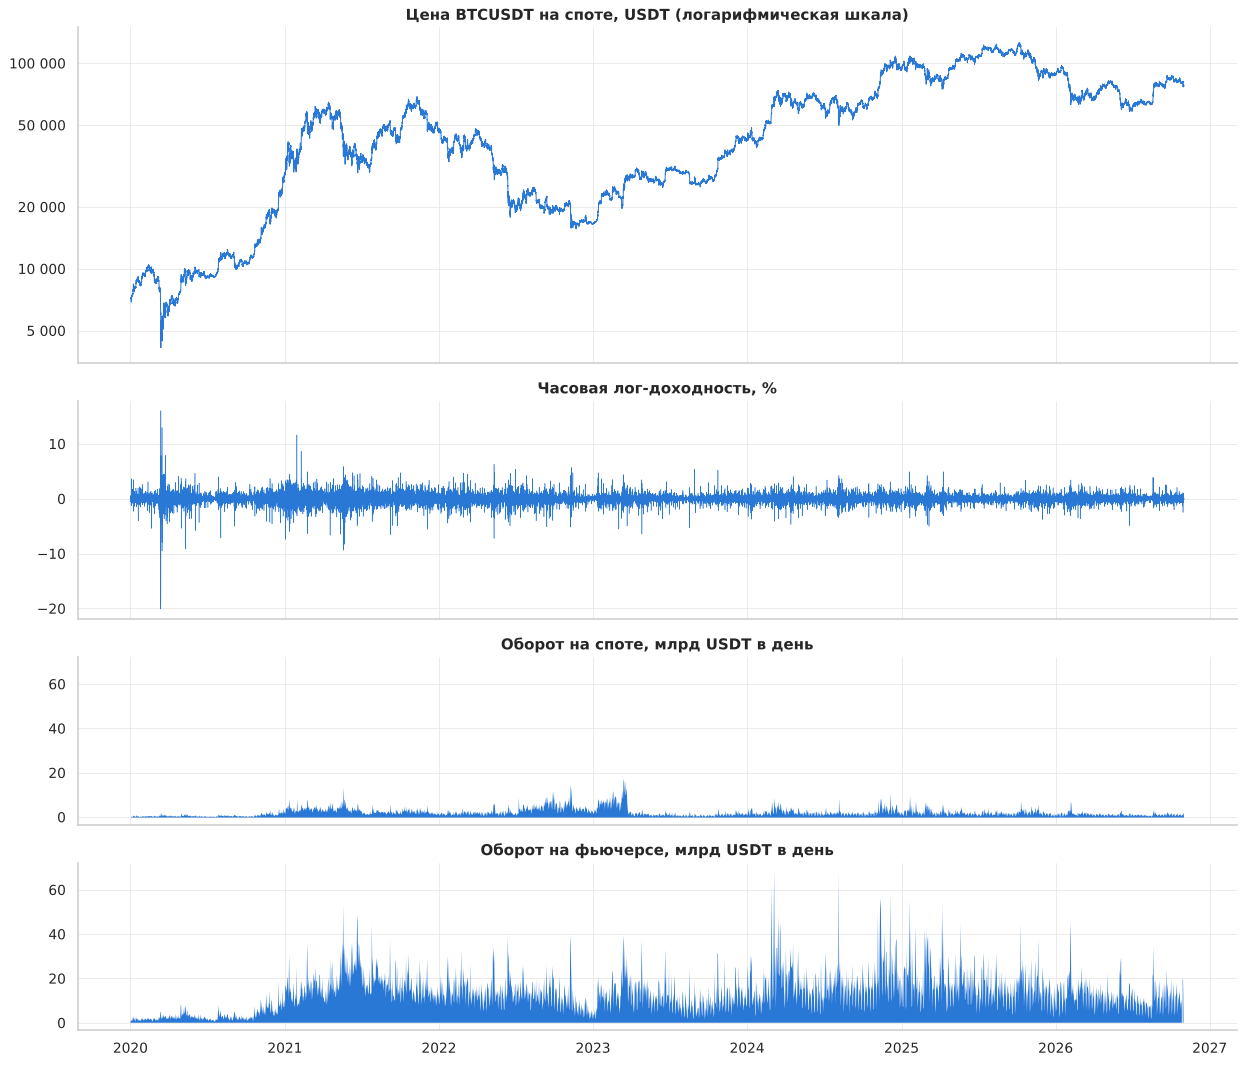

In [21]:
daily_volume = df[['quote_volume', 'fut_quote_volume']].resample('D').sum(min_count=1) / 1e9   # млрд USDT в день

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1.3, 1, 1]})

axes[0].plot(df.index, df['close'], color=BLUE, linewidth=0.8)
axes[0].set_yscale('log')
axes[0].set_yticks([5_000, 10_000, 20_000, 50_000, 100_000])
axes[0].set_yticklabels(['5 000', '10 000', '20 000', '50 000', '100 000'])
axes[0].set_title('Цена BTCUSDT на споте, USDT (логарифмическая шкала)')

axes[1].plot(df.index, df['ret'] * 100, color=BLUE, linewidth=0.4)
axes[1].set_title('Часовая лог-доходность, %')

axes[2].fill_between(daily_volume.index, daily_volume['quote_volume'], color=BLUE, linewidth=0)
axes[2].set_title('Оборот на споте, млрд USDT в день')

axes[3].fill_between(daily_volume.index, daily_volume['fut_quote_volume'], color=BLUE, linewidth=0)
axes[3].set_title('Оборот на фьючерсе, млрд USDT в день')
axes[3].sharey(axes[2])

plt.tight_layout()
plt.show()

Что видно:

* цена: 7.2 тысячи в начале 2020 года, минимум 3.8 тысячи в марте 2020, максимум 126 тысяч в октябре 2025, в конце периода 77.6 тысячи;
* доходности колеблются около нуля, но размах меняется: бурные и спокойные периоды идут подряд. Самый бурный — март 2020;
* оборот фьючерса в несколько раз больше спотового;
* у спотового оборота есть ступенька с середины 2022 года до марта 2023. По времени она совпадает с периодом нулевой комиссии Binance на спотовую торговлю BTC.

Цены и объёмы разных лет напрямую сравнивать нельзя, нужны относительные величины.

# 5. Выбросы и скачки цены

## 5.1. Boxplot и правило 1.5 IQR

Как на лекции, рисуем boxplot для каждого признака на отдельном графике. Звёздочкой отмечается всё, что лежит дальше 1.5 межквартильных размахов (IQR) от «ящика».

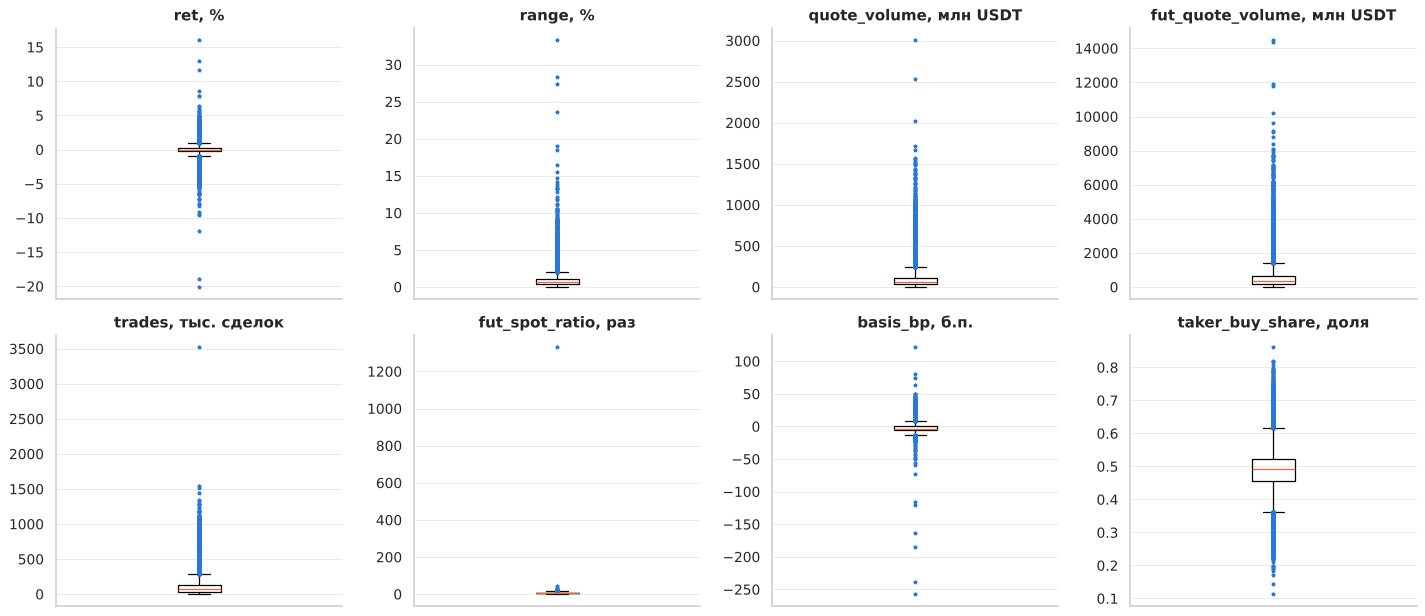

In [22]:
# признак: (на что делим для удобных единиц, подпись)
box_units = {
    'ret': (0.01, 'ret, %'),
    'range': (0.01, 'range, %'),
    'quote_volume': (1e6, 'quote_volume, млн USDT'),
    'fut_quote_volume': (1e6, 'fut_quote_volume, млн USDT'),
    'trades': (1e3, 'trades, тыс. сделок'),
    'fut_spot_ratio': (1, 'fut_spot_ratio, раз'),
    'basis_bp': (1, 'basis_bp, б.п.'),
    'taker_buy_share': (1, 'taker_buy_share, доля'),
}
box_cols = list(box_units)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, box_cols):
    scale, title = box_units[col]
    ax.boxplot(df[col].dropna() / scale, sym='*', flierprops={'markersize': 3, 'markeredgecolor': BLUE})
    ax.set_title(title)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [23]:
def iqr_outlier_share(x):
    # Доля значений за пределами 1.5 IQR от квартилей, в процентах
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean() * 100


pd.DataFrame({
    'скошенность (skew)': df[box_cols].skew(),
    'за пределами 1.5 IQR, %': df[box_cols].apply(iqr_outlier_share),
}).round(2)

,скошенность (skew),"за пределами 1.5 IQR, %"
ret,-0.9300,9.0200
range,6.8300,6.2300
quote_volume,4.3200,6.9900
fut_quote_volume,4.1300,7.0800
trades,3.2000,7.8300
fut_spot_ratio,157.84,0.3200
basis_bp,-1.7900,7.3700
taker_buy_share,-0.0500,4.5400


Что видно:

* по правилу 1.5 IQR выбросами считаются 4.5–9% значений почти у каждого признака. Это не ошибки, а тяжёлые хвосты: редкие, но очень большие значения;
* удалять по этому правилу нельзя, мы выбросили бы самые важные для рынка часы;
* отдельный случай — `fut_spot_ratio` со значением больше 1 300, разберём его ниже.

## 5.2. Скачки цены

Для цены «выброс» — это необычно большое движение за час. «Необычно» зависит от периода: 2% за час в спокойном 2023 году — событие, а в марте 2020 — обычный час. Поэтому сравниваем доходность не с общим разбросом, а с **волатильностью предыдущей недели**:

$$z_t = \frac{r_t}{\sigma_{t-1}}, \quad \sigma_{t-1}\text{ — стандартное отклонение доходностей за 168 часов до часа } t$$

Скачком считаем час, где $|z_t| > 6$.

In [24]:
sigma_prev_week = df['ret'].rolling(168).std().shift(1)
df['ret_z'] = df['ret'] / sigma_prev_week
df['fut_ret'] = np.log(df['fut_close']).diff()

jumps = df[df['ret_z'].abs() > 6]
print(f'Скачков (|z| > 6): {len(jumps)} из {len(df)} часов ({len(jumps) / len(df):.2%})')
print('\nСкачков по годам:')
print(jumps.groupby('year').size().to_string())

Скачков (|z| > 6): 148 из 59904 часов (0.25%)

Скачков по годам:
year
2020    27
2021    15
2022    24
2023    33
2024    17
2025    15
2026    17


In [25]:
top = df.loc[df['ret'].abs().nlargest(12).index,
             ['close', 'ret', 'fut_ret', 'ret_z', 'volume_rel', 'spot_halt']].copy()
top['ret'] = (top['ret'] * 100).round(2)
top['fut_ret'] = (top['fut_ret'] * 100).round(2)
top.columns = ['цена закрытия', 'доходность спот, %', 'доходность фьючерс, %',
               'z к прошлой неделе', 'оборот к обычному, раз', 'остановка спота']
top

,цена закрытия,"доходность спот, %","доходность фьючерс, %",z к прошлой неделе,"оборот к обычному, раз",остановка спота
time,,,,,,
2020-03-12 10:00:00,"6,014.90",-20.1000,-20.7100,-28.2778,9.4596,False
2020-03-12 23:00:00,"4,800.00",-18.9700,-19.6100,-10.8021,9.2015,False
2020-03-13 02:00:00,"4,848.71",16.0300,15.0800,6.5435,8.1666,False
2020-03-15 21:00:00,"5,903.77",12.9500,13.0100,4.0950,3.9294,False
2020-03-13 01:00:00,"4,130.64",-11.9400,-11.1800,-5.2336,4.8791,False
2021-01-29 08:00:00,"36,240.24",11.6100,11.9300,10.3178,6.1532,False
2020-03-15 22:00:00,"5,367.76",-9.5200,-9.5800,-2.8633,3.9469,False
2021-05-19 12:00:00,"35,234.62",-9.3800,-9.9000,-6.7329,5.3755,False
2020-05-10 00:00:00,"8,703.67",-9.1700,-9.3800,-13.8574,14.4918,False


Скачок может быть настоящим движением рынка или ошибкой в данных («плохой тик»). Отличить их помогает второй источник: спот и фьючерс — разные рынки с отдельными сделками. Если скачок есть на обоих, это рынок, а не ошибка записи.

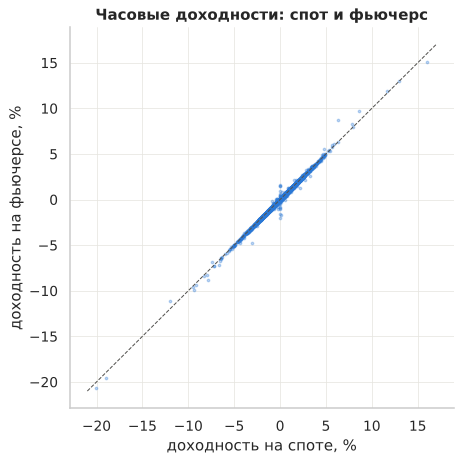

Корреляция доходностей спота и фьючерса: 0.9987
Часов, где они расходятся больше чем на 1 п.п.: 10

Самые большие расхождения:


,ret,fut_ret,volume_rel,spot_halt
time,,,,
2020-03-13 03:00:00,6.3600,8.7300,5.6197,False
2020-12-21 17:00:00,0.0000,-2.0500,0.0000,True
2023-03-24 11:00:00,0.1400,-1.6900,0.1061,False
2020-03-13 00:00:00,-3.0700,-4.7600,6.1712,False
2021-02-11 03:00:00,0.0000,1.5800,0.0000,True
2021-02-11 04:00:00,0.0000,-1.5600,0.0000,True


In [26]:
both = df[['ret', 'fut_ret']].dropna() * 100
diff = (both['ret'] - both['fut_ret']).abs()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(both['ret'], both['fut_ret'], s=4, alpha=0.3, color=BLUE)
ax.plot([-21, 17], [-21, 17], color=GRAY, linewidth=0.8, linestyle='--')
ax.set_xlabel('доходность на споте, %')
ax.set_ylabel('доходность на фьючерсе, %')
ax.set_title('Часовые доходности: спот и фьючерс')
plt.show()

print(f'Корреляция доходностей спота и фьючерса: {both["ret"].corr(both["fut_ret"]):.4f}')
print(f'Часов, где они расходятся больше чем на 1 п.п.: {(diff > 1).sum()}')
print('\nСамые большие расхождения:')
worst = diff.nlargest(6).index
display(df.loc[worst, ['ret', 'fut_ret', 'volume_rel', 'spot_halt']].assign(
    ret=lambda t: (t['ret'] * 100).round(2), fut_ret=lambda t: (t['fut_ret'] * 100).round(2)))

Что видно:

* скачков с $|z| > 6$ всего 148 (0.25% часов), по 15–33 в год;
* самые крупные движения были в марте 2020: 7 из 12 крупнейших часов, до −20% за час;
* два крупных скачка совпадают с новостями: 29.01.2021 (Илон Маск добавил #bitcoin в профиль) и 08.02.2021 (Tesla сообщила о покупке биткоина). Это аргумент в пользу новостных признаков во втором семестре;
* каждый крупный скачок есть и на фьючерсе: корреляция часовых доходностей 0.9987, расхождений больше 1 п.п. всего 10, из них 7 — часы вокруг остановок спота.

Скачки — это реальные движения рынка, а не ошибки в данных.

## 5.3. Что делаем с выбросами

Сравним два способа «смягчить» хвосты: логарифм для объёмов и ограничение (винзоризацию) для доходностей — значения за 0.1% и 99.9% квантилями заменяются на сами квантили.

In [27]:
low, high = df['ret'].quantile([0.001, 0.999])
ret_clipped = df['ret'].clip(low, high)

print(f'Границы винзоризации: {low:.2%} и {high:.2%}\n')
display(pd.DataFrame({
    'std': [df['ret'].std(), ret_clipped.std()],
    'skew': [df['ret'].skew(), ret_clipped.skew()],
    'эксцесс': [df['ret'].kurt(), ret_clipped.kurt()],
}, index=['доходность как есть', 'после винзоризации']))

display(pd.DataFrame({
    'skew': [df['quote_volume'].skew(), df['log_volume'].skew(),
             df['fut_quote_volume'].skew(), df['log_fut_volume'].skew()],
    'за пределами 1.5 IQR, %': [iqr_outlier_share(df['quote_volume']), iqr_outlier_share(df['log_volume'].dropna()),
                               iqr_outlier_share(df['fut_quote_volume'].dropna()), iqr_outlier_share(df['log_fut_volume'].dropna())],
}, index=['оборот спот', 'log(оборот спот)', 'оборот фьючерс', 'log(оборот фьючерс)']).round(2))

Границы винзоризации: -4.15% и 3.80%



,std,skew,эксцесс
доходность как есть,0.0065,-0.9302,54.8848
после винзоризации,0.0061,-0.1986,8.8527


,skew,"за пределами 1.5 IQR, %"
оборот спот,4.3200,6.9900
log(оборот спот),0.0900,0.2800
оборот фьючерс,4.1300,7.0900
log(оборот фьючерс),-0.3400,1.6100


У `fut_spot_ratio` скошенность больше 100. Посмотрим, откуда она берётся.

In [28]:
top_ratio = df['fut_spot_ratio'].nlargest(5)
display(df.loc[top_ratio.index, ['quote_volume', 'fut_quote_volume', 'fut_spot_ratio', 'volume_rel']])

cap = df['fut_spot_ratio'].quantile(0.999)
print(f'99.9% квантиль отношения: {cap:.1f}')
print(f'Скошенность до ограничения: {df["fut_spot_ratio"].skew():.1f}')
df['fut_spot_ratio'] = df['fut_spot_ratio'].clip(upper=cap)
print(f'Скошенность после ограничения: {df["fut_spot_ratio"].skew():.2f}')

,quote_volume,fut_quote_volume,fut_spot_ratio,volume_rel
time,,,,
2021-04-25 04:00:00,"292,226.01","388,674,985.40","1,330.05",0.0019
2023-03-24 11:00:00,"35,521,462.04","1,640,189,312.07",46.1746,0.1061
2025-05-24 16:00:00,"31,586,725.20","1,100,461,765.18",34.8394,0.3317
2025-05-24 15:00:00,"41,641,355.10","1,147,295,288.79",27.5518,0.4373
2025-03-22 21:00:00,"18,178,406.71","459,437,190.85",25.2738,0.4198


99.9% квантиль отношения: 17.4
Скошенность до ограничения: 157.8
Скошенность после ограничения: 0.29


Что делаем с выбросами:

* доходности не удаляем: это реальные события;
* для признаков в линейных моделях можно ограничивать крайние значения (эксцесс падает с 54.9 до 8.9). Границы нужно считать только по обучающей выборке;
* объёмы логарифмируем: скошенность у спота падает с 4.3 до 0.09;
* `fut_spot_ratio` ограничили сверху значением 17.4 (99.9% квантиль). Значение 1 330 получилось в час перед остановкой спота 25.04.2021, когда спот почти не торговался;
* при оценке моделей смотрим не только MSE, но и MAE: MSE слишком сильно реагирует на редкие большие ошибки.

# 6. Распределение доходностей

Сравним распределение часовых доходностей с нормальным (с тем же средним и стандартным отклонением). Справа — QQ-график: если бы доходности были нормальными, точки лежали бы на прямой.

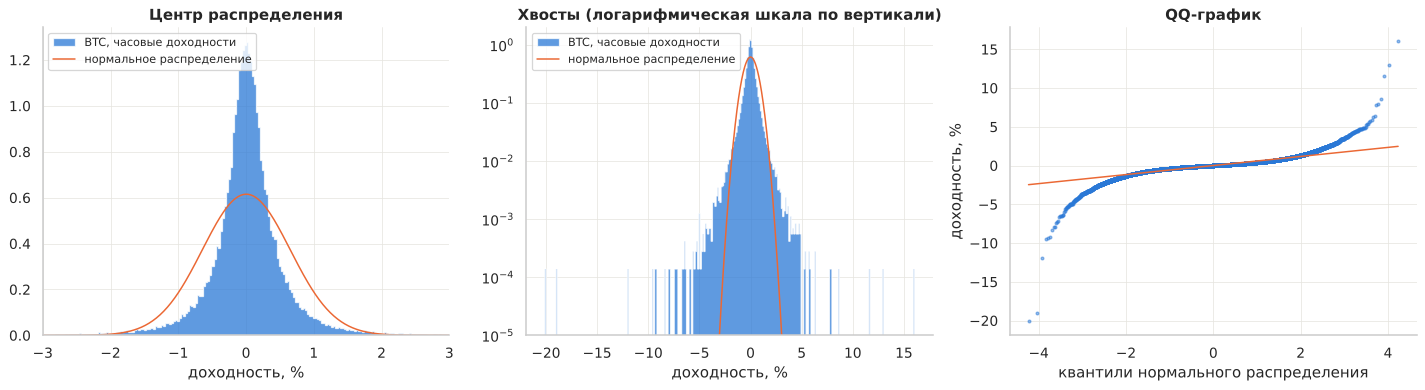

In [29]:
r = df['ret'].dropna()
mu, sigma = r.mean(), r.std()
grid = np.linspace(r.min(), r.max(), 2000)
normal_pdf = stats.norm.pdf(grid, mu, sigma)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(r * 100, bins=200, range=(-3, 3), density=True, color=BLUE, alpha=0.75,
             histtype='stepfilled', label='BTC, часовые доходности')
axes[0].plot(grid * 100, normal_pdf / 100, color=ORANGE, label='нормальное распределение')
axes[0].set_xlim(-3, 3)
axes[0].set_xlabel('доходность, %')
axes[0].set_title('Центр распределения')
axes[0].legend(fontsize=9, loc='upper left')

axes[1].hist(r * 100, bins=300, density=True, color=BLUE, alpha=0.75,
             histtype='stepfilled', label='BTC, часовые доходности')
axes[1].plot(grid * 100, normal_pdf / 100, color=ORANGE, label='нормальное распределение')
axes[1].set_yscale('log')
axes[1].set_ylim(1e-5, 2)
axes[1].set_xlabel('доходность, %')
axes[1].set_title('Хвосты (логарифмическая шкала по вертикали)')
axes[1].legend(fontsize=9, loc='upper left')

(osm, osr), (slope, intercept, _) = stats.probplot(r, dist='norm')
axes[2].scatter(osm, osr * 100, s=5, color=BLUE, alpha=0.5)
axes[2].plot(osm, (slope * osm + intercept) * 100, color=ORANGE)
axes[2].set_xlabel('квантили нормального распределения')
axes[2].set_ylabel('доходность, %')
axes[2].set_title('QQ-график')

plt.tight_layout()
plt.show()

Те же характеристики числами, для часового и дневного шага. Дневные доходности получаем из тех же данных: берём цену закрытия последнего часа каждых суток.

In [30]:
def return_stats(x):
    x = x.dropna()
    z = (x - x.mean()) / x.std()
    return pd.Series({
        'наблюдений': len(x),
        'среднее, %': x.mean() * 100,
        'std, %': x.std() * 100,
        'минимум, %': x.min() * 100,
        'максимум, %': x.max() * 100,
        'скошенность': x.skew(),
        'эксцесс (у нормального 0)': x.kurt(),
        'доля |z| > 3, % (у нормального 0.27)': (z.abs() > 3).mean() * 100,
        'доля растущих периодов, %': (x > 0).mean() * 100,
        'автокорреляция, лаг 1': x.autocorr(1),
        'p-value теста Харке–Бера': stats.jarque_bera(x).pvalue,
    })


daily_close = df['close'].resample('D').last()
daily_ret = np.log(daily_close).diff()

pd.DataFrame({'1 час': return_stats(df['ret']), '1 день': return_stats(daily_ret)}).round(4)

,1 час,1 день
наблюдений,"59,903.00","2,495.00"
"среднее, %",0.0040,0.0953
"std, %",0.6484,3.1899
"минимум, %",-20.1033,-50.2607
"максимум, %",16.0280,17.8449
скошенность,-0.9302,-1.5531
эксцесс (у нормального 0),54.8848,27.5937
"доля |z| > 3, % (у нормального 0.27)",1.8046,1.4429
"доля растущих периодов, %",50.6669,50.8216
"автокорреляция, лаг 1",-0.0213,-0.0725


Что видно:

* распределение не нормальное: острый пик и тяжёлые хвосты, эксцесс 54.9. Тест Харке–Бера нормальность отвергает;
* за три стандартных отклонения выходит 1.80% часов, у нормального распределения было бы 0.27%;
* падения резче подъёмов: худший час −20.1%, лучший +16.0%, скошенность −0.93;
* на дневном шаге то же самое: эксцесс 27.6, растущих дней 50.8%.

# 7. Волатильность

Волатильность — это размах колебаний цены. Считаем её как стандартное отклонение часовых доходностей в скользящем окне и переводим в годовое выражение (умножаем на $\sqrt{24 \cdot 365}$), чтобы числа были привычными: «60% годовых».

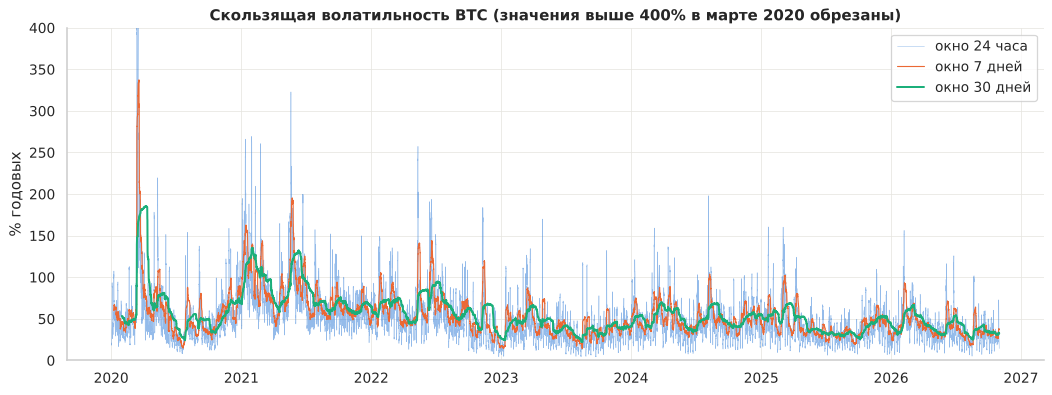

Волатильность за весь период: 60.7% годовых


In [31]:
HOURS_PER_YEAR = 24 * 365
annualize = np.sqrt(HOURS_PER_YEAR) * 100

vol = pd.DataFrame({
    'окно 24 часа': df['ret'].rolling(24).std() * annualize,
    'окно 7 дней': df['ret'].rolling(168).std() * annualize,
    'окно 30 дней': df['ret'].rolling(720).std() * annualize,
})

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(vol.index, vol['окно 24 часа'], color=BLUE, linewidth=0.4, alpha=0.5, label='окно 24 часа')
ax.plot(vol.index, vol['окно 7 дней'], color=ORANGE, linewidth=0.9, label='окно 7 дней')
ax.plot(vol.index, vol['окно 30 дней'], color=AQUA, linewidth=1.6, label='окно 30 дней')
ax.set_ylim(0, 400)
ax.set_ylabel('% годовых')
ax.set_title('Скользящая волатильность BTC (значения выше 400% в марте 2020 обрезаны)')
ax.legend()
plt.show()

print(f'Волатильность за весь период: {df["ret"].std() * annualize:.1f}% годовых')

In [32]:
by_year = df.groupby('year').agg(
    доходность_за_год=('ret', lambda x: (np.exp(x.sum()) - 1) * 100),
    волатильность=('ret', lambda x: x.std() * annualize),
    худший_час=('ret', lambda x: x.min() * 100),
    лучший_час=('ret', lambda x: x.max() * 100),
    скачков=('ret_z', lambda x: (x.abs() > 6).sum()),
)
by_year.columns = ['доходность за год, %', 'волатильность, % годовых', 'худший час, %', 'лучший час, %', 'скачков (|z| > 6)']
by_year.round(1)

,"доходность за год, %","волатильность, % годовых","худший час, %","лучший час, %",скачков (|z| > 6)
year,,,,,
2020,303.00,75.2000,-20.1000,16.0000,27
2021,59.8000,86.1000,-9.4000,11.6000,15
2022,-64.2000,63.8000,-7.2000,6.3000,24
2023,155.60,42.5000,-6.4000,5.4000,33
2024,121.30,52.6000,-4.7000,4.2000,17
2025,-6.3000,44.5000,-5.0000,4.9000,15
2026,-11.5000,42.2000,-4.9000,3.9000,17


**Кластеризация волатильности.** Проверим простым способом, без формул: разобьём все часы на 10 равных групп по размеру движения в текущем часе и посмотрим, каким в среднем было движение в **следующем** часе.

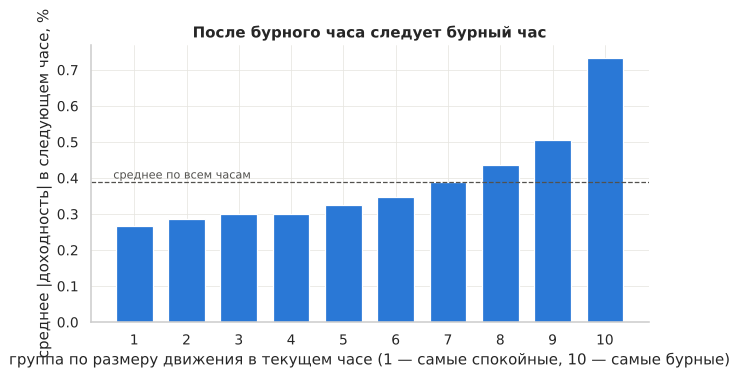

ret,1,2,3,4,5,6,7,8,9,10
"среднее |доходность| следующего часа, %",0.2670,0.2850,0.3010,0.2990,0.3240,0.3470,0.3890,0.4360,0.5050,0.7330


In [33]:
abs_ret_group = pd.qcut(df['ret'].abs(), 10, labels=range(1, 11))
next_move = df.groupby(abs_ret_group, observed=True)['target_abs'].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(next_move.index.astype(str), next_move.values, color=BLUE, width=0.7)
ax.axhline(df['target_abs'].mean() * 100, color=GRAY, linestyle='--', linewidth=1)
ax.text(-0.4, df['target_abs'].mean() * 100 + 0.01, 'среднее по всем часам', color=GRAY, fontsize=9)
ax.set_xlabel('группа по размеру движения в текущем часе (1 — самые спокойные, 10 — самые бурные)')
ax.set_ylabel('среднее |доходность| в следующем часе, %')
ax.set_title('После бурного часа следует бурный час')
plt.show()

next_move.round(3).to_frame('среднее |доходность| следующего часа, %').T

Что видно:

* волатильность за весь период 60.7% годовых, но она сильно меняется: 30-дневная была от 22% до 185%;
* по годам она снижается: 75% в 2020, 86% в 2021, 42% в 2026;
* волатильность кластеризуется: после самых спокойных часов следующее движение в среднем 0.27%, после самых бурных 0.73%.

Размер будущего движения предсказуем. Данные разных лет находятся в разном масштабе, это нужно учесть при обучении.

# 8. Автокорреляция: ACF и PACF

**ACF** (автокорреляционная функция) отвечает на вопрос: насколько значение ряда сейчас похоже на значение $k$ часов назад? Это обычная корреляция Пирсона между рядом и им же, сдвинутым на $k$ шагов (лаг).

**PACF** (частная автокорреляция) показывает связь с лагом $k$ **за вычетом** влияния более близких лагов. Пример: если сегодня похоже на вчера, а вчера на позавчера, то сегодня будет похоже и на позавчера «по цепочке». PACF убирает эту цепочку и оставляет только прямую связь.

Голубая полоса на графиках — граница случайного шума: столбики внутри неё неотличимы от нуля.

Смотрим четыре ряда на лагах до 72 часов (трое суток): цену, доходность, модуль доходности (размер движения) и логарифм оборота.

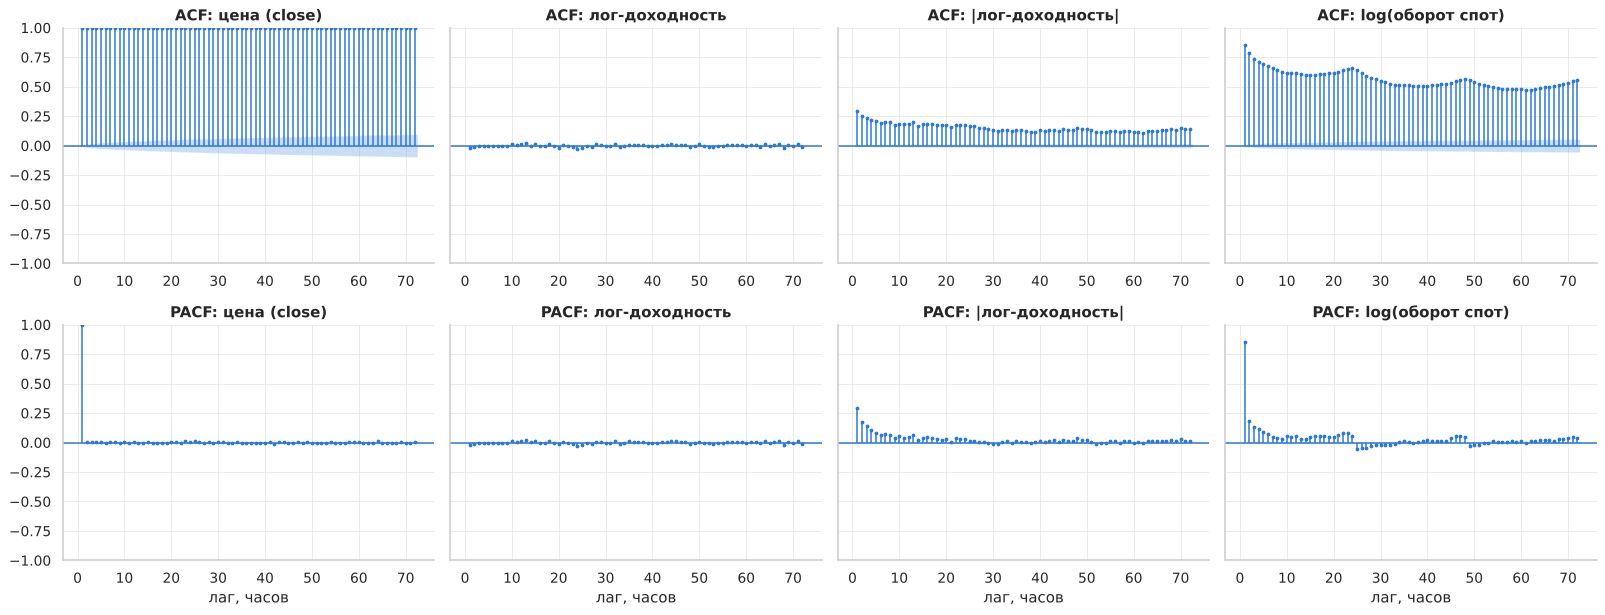

In [34]:
acf_series = {
    'цена (close)': df['close'],
    'лог-доходность': df['ret'].dropna(),
    '|лог-доходность|': df['ret'].abs().dropna(),
    'log(оборот спот)': df['log_volume'].dropna(),
}

fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey=True)
for j, (name, series) in enumerate(acf_series.items()):
    plot_acf(series, lags=72, ax=axes[0, j], zero=False, title=f'ACF: {name}', color=BLUE,
             vlines_kwargs={'colors': BLUE}, markersize=2)
    plot_pacf(series, lags=72, ax=axes[1, j], zero=False, method='ywm', title=f'PACF: {name}', color=BLUE,
              vlines_kwargs={'colors': BLUE}, markersize=2)
    axes[1, j].set_xlabel('лаг, часов')
plt.tight_layout()
plt.show()

На общем масштабе автокорреляция доходностей сливается с нулём. Посмотрим на числа и добавим тест Льюнга–Бокса: он проверяет сразу группу лагов и отвечает, есть ли в ряду хоть какая-то автокорреляция (маленькое p-value — есть).

In [35]:
lags = [1, 2, 3, 6, 12, 24, 48, 168]
ret_clean = df['ret'].dropna()

acf_table = pd.DataFrame({
    'доходность': acf(ret_clean, nlags=168)[lags],
    '|доходность|': acf(ret_clean.abs(), nlags=168)[lags],
    'log(оборот спот)': acf(df['log_volume'].dropna(), nlags=168)[lags],
}, index=[f'лаг {k}' for k in lags])
display(acf_table.round(4))

print(f'Граница шума (95%): ±{1.96 / np.sqrt(len(ret_clean)):.4f}')

lb = pd.concat([
    acorr_ljungbox(ret_clean, lags=[24]).assign(ряд='доходность'),
    acorr_ljungbox(ret_clean.abs(), lags=[24]).assign(ряд='|доходность|'),
]).set_index('ряд')
lb.columns = ['статистика Льюнга–Бокса (24 лага)', 'p-value']
lb

,доходность,|доходность|,log(оборот спот)
лаг 1,-0.0213,0.2953,0.8561
лаг 2,-0.0126,0.2498,0.7822
лаг 3,-0.0005,0.2345,0.7383
лаг 6,-0.0032,0.1943,0.6758
лаг 12,0.0128,0.1835,0.6125
лаг 24,-0.0278,0.1766,0.6586
лаг 48,-0.0132,0.1516,0.5692
лаг 168,0.0116,0.1434,0.6563


Граница шума (95%): ±0.0080


,статистика Льюнга–Бокса (24 лага),p-value
ряд,,
доходность,180.73,0.0000
|доходность|,"55,206.40",0.0000


Что видно:

* цена: ACF около 1 на всех лагах, в PACF только первый лаг. Так выглядит случайное блуждание, поэтому прогноз «цена не изменится» будет сильным бейзлайном;
* доходность: автокорреляции не больше 0.03 по модулю. Формально они значимы (данных много, тест Льюнга–Бокса это показывает), но связь очень слабая;
* модуль доходности: 0.30 на первом лаге, 0.18 через сутки, 0.14 через неделю. Волатильность долго «помнит» прошлое;
* оборот: 0.86 на первом лаге и пики на 24, 48 и 72 часах, это суточная сезонность.

По прошлым доходностям будущую почти не предсказать, а волатильность и объём по прошлым значениям предсказываются.

# 9. Стационарность: тесты ADF и KPSS

Ряд называют **стационарным**, если его свойства (средний уровень, разброс) не меняются со временем. Большинству моделей нужны именно такие ряды: если средний уровень «уплывает», закономерности из прошлого перестают работать в будущем.

Два теста смотрят на вопрос с разных сторон:

* **ADF** (расширенный тест Дики–Фуллера). Нулевая гипотеза: ряд **нестационарен** (есть «единичный корень», ряд блуждает как случайное блуждание). Маленькое p-value (< 0.05) — отвергаем, ряд стационарен.
* **KPSS**. Нулевая гипотеза обратная: ряд **стационарен**. Маленькое p-value — ряд нестационарен.

Если оба теста согласны, выводу можно доверять. Если расходятся, ряд ведёт себя «промежуточно», и это тоже полезная информация. В `statsmodels` p-value теста KPSS ограничено диапазоном от 0.01 до 0.10.

In [36]:
def stationarity_tests(series):
    series = series.dropna()
    adf_stat, adf_p = adfuller(series, maxlag=24, autolag='AIC')[:2]
    kpss_stat, kpss_p = kpss(series, regression='c', nlags='auto')[:2]

    if adf_p < 0.05 and kpss_p >= 0.05:
        verdict = 'стационарен'
    elif adf_p >= 0.05 and kpss_p < 0.05:
        verdict = 'нестационарен'
    elif adf_p < 0.05 and kpss_p < 0.05:
        verdict = 'тесты расходятся: нет единичного корня, но уровень меняется'
    else:
        verdict = 'тесты расходятся: данных недостаточно для вывода'
    return pd.Series({'ADF статистика': adf_stat, 'ADF p-value': adf_p,
                      'KPSS статистика': kpss_stat, 'KPSS p-value': kpss_p, 'вывод': verdict})


test_series = {
    'цена (close)': df['close'],
    'log(цена)': np.log(df['close']),
    'лог-доходность': df['ret'],
    '|лог-доходность|': df['ret'].abs(),
    'волатильность за 24 часа': df['vol_24h'],
    'log(оборот спот)': df['log_volume'],
    'log(оборот фьючерс)': df['log_fut_volume'],
    'оборот спот к медиане за 7 дней (log)': np.log(df['volume_rel'].where(df['volume_rel'] > 0)),
    'отношение оборотов фьючерс / спот': df['fut_spot_ratio'],
    'базис, б.п.': df['basis_bp'],
}

stationarity = pd.DataFrame({name: stationarity_tests(series) for name, series in test_series.items()}).T
with pd.option_context('display.max_colwidth', 80):
    display(stationarity)

,ADF статистика,ADF p-value,KPSS статистика,KPSS p-value,вывод
цена (close),-1.4124,0.5763,27.5265,0.0100,нестационарен
log(цена),-2.0796,0.2528,26.2838,0.0100,нестационарен
лог-доходность,-51.0569,0.0000,0.2063,0.1000,стационарен
|лог-доходность|,-23.8004,0.0000,8.7517,0.0100,"тесты расходятся: нет единичного корня, но уровень меняется"
волатильность за 24 часа,-16.7681,0.0000,8.1951,0.0100,"тесты расходятся: нет единичного корня, но уровень меняется"
log(оборот спот),-13.4011,0.0000,2.9886,0.0100,"тесты расходятся: нет единичного корня, но уровень меняется"
log(оборот фьючерс),-13.6828,0.0000,9.1833,0.0100,"тесты расходятся: нет единичного корня, но уровень меняется"
оборот спот к медиане за 7 дней (log),-27.0436,0.0000,0.1664,0.1000,стационарен
отношение оборотов фьючерс / спот,-8.7905,0.0000,16.9323,0.0100,"тесты расходятся: нет единичного корня, но уровень меняется"
"базис, б.п.",-11.7159,0.0000,8.6372,0.0100,"тесты расходятся: нет единичного корня, но уровень меняется"


Что видно:

* цена и логарифм цены нестационарны, оба теста согласны;
* доходность стационарна, оба теста согласны. Поэтому прогнозируем доходность, а не цену;
* волатильность, обороты и базис: ADF показывает стационарность, KPSS — нет. Эти ряды не уходят в тренд, как цена, но их средний уровень со временем меняется, это видно и на графиках;
* оборот относительно медианы за 7 дней стационарен по обоим тестам.

В модели лучше использовать относительные признаки.

# 10. Сезонность: час суток, день недели, месяц

Криптовалюты торгуются круглосуточно и без выходных, но люди и фонды работают по расписанию. Сводные таблицы «день недели × час» покажут, когда рынок активнее. В ячейках — отношение к среднему по всему периоду: 1.0 значит «как обычно», 1.5 — в полтора раза больше.

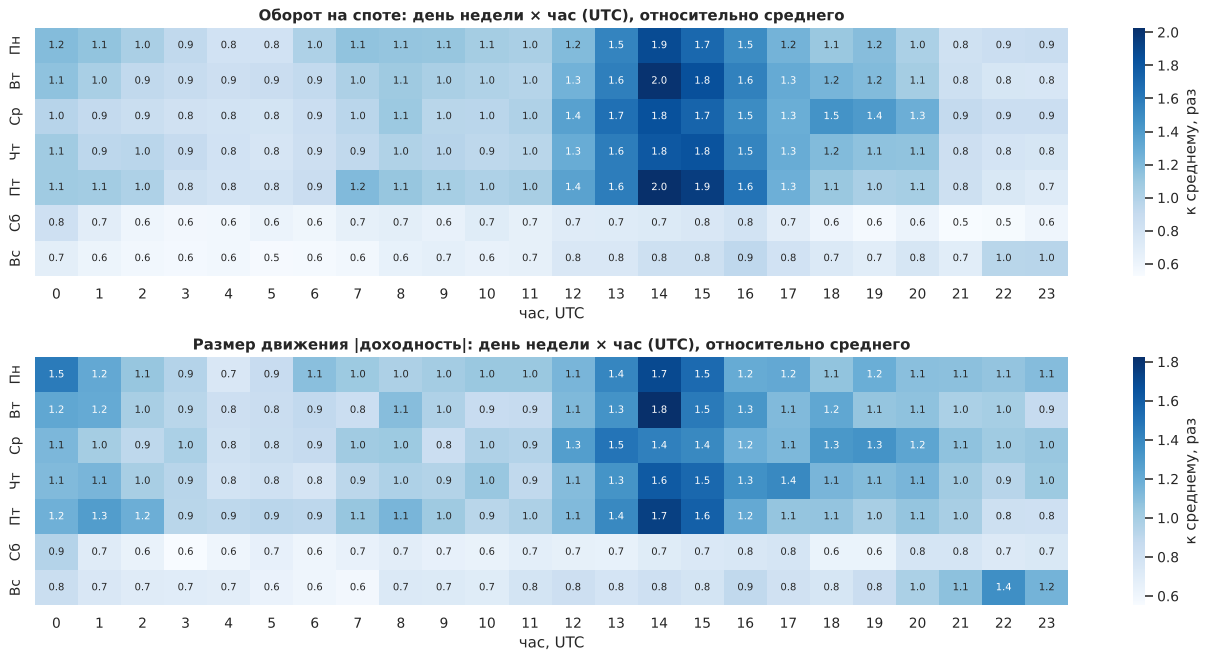

In [37]:
df['abs_ret'] = df['ret'].abs()

pivot_volume = df.pivot_table(index='weekday', columns='hour', values='quote_volume',
                              aggfunc='mean', observed=True) / df['quote_volume'].mean()
pivot_move = df.pivot_table(index='weekday', columns='hour', values='abs_ret',
                            aggfunc='mean', observed=True) / df['abs_ret'].mean()

fig, axes = plt.subplots(2, 1, figsize=(15, 7.5))
sns.heatmap(pivot_volume, cmap='Blues', annot=True, fmt='.1f', annot_kws={'size': 8},
            cbar_kws={'label': 'к среднему, раз'}, ax=axes[0])
axes[0].set_title('Оборот на споте: день недели × час (UTC), относительно среднего')
sns.heatmap(pivot_move, cmap='Blues', annot=True, fmt='.1f', annot_kws={'size': 8},
            cbar_kws={'label': 'к среднему, раз'}, ax=axes[1])
axes[1].set_title('Размер движения |доходность|: день недели × час (UTC), относительно среднего')
for ax in axes:
    ax.set_xlabel('час, UTC')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [38]:
by_session = df.groupby(['session', 'is_weekend'], observed=True).agg(
    часов=('ret', 'size'),
    средняя_доходность_бп=('target', lambda x: x.mean() * 10_000),
    средний_размер_движения=('target_abs', lambda x: x.mean() * 100),
    средний_оборот=('quote_volume', lambda x: x.mean() / 1e6),
    доля_роста=('target', lambda x: (x > 0).mean() * 100),
)
by_session.columns = ['часов', 'средняя доходность след. часа, б.п.', 'среднее |доходность| след. часа, %',
                      'средний оборот, млн USDT', 'доля часов с ростом, %']
by_session.round(2)

часов  средняя доходность след. часа, б.п.  среднее |доходность| след. часа, %  средний оборот, млн USDT  доля часов с ростом, %
session             is_weekend                                                                                                                                  
Азия (00–08 UTC)    False       14264                               0.2600                              0.3800                   87.7600                 50.1800
                    True         5704                              -0.5600                              0.2600                   57.0000                 49.8900
Европа (08–16 UTC)  False       14264                               0.3300                              0.4800                    124.57                 49.9400
                    True         5704                               0.2800                              0.2900                   66.3800                 51.0000
Америка (16–24 UTC) False       14264                               1.0000                              0.4200                    102.48                 51.7100
                    True         5704                               0.4900                              0.3500                   67.0100                 51.5300

Доходность по месяцам (в процентах). Синий — рост, красный — падение.

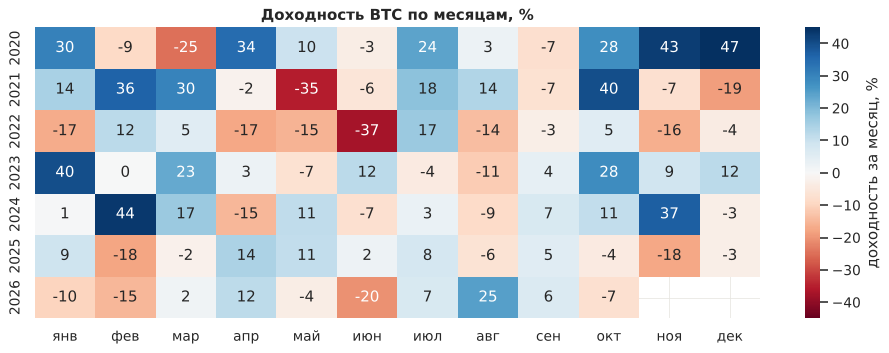

Средняя доходность по месяцам, %:
янв    9.7000
фев    7.3000
мар    7.2000
апр    4.2000
май   -4.2000
июн   -8.5000
июл   10.5000
авг    0.1000
сен    0.8000
окт   14.5000
ноя    8.0000
дек    5.1000


In [39]:
monthly = (np.exp(df['ret'].resample('MS').sum()) - 1) * 100
monthly_table = monthly.to_frame('ret').assign(year=monthly.index.year, month=monthly.index.month) \
                       .pivot(index='year', columns='month', values='ret')
monthly_table.columns = ['янв', 'фев', 'мар', 'апр', 'май', 'июн', 'июл', 'авг', 'сен', 'окт', 'ноя', 'дек']

fig, ax = plt.subplots(figsize=(13, 4.2))
sns.heatmap(monthly_table, cmap='RdBu', center=0, vmin=-45, vmax=45, annot=True, fmt='.0f',
            cbar_kws={'label': 'доходность за месяц, %'}, ax=ax)
ax.set_title('Доходность BTC по месяцам, %')
ax.set_xlabel('')
ax.set_ylabel('')
plt.show()

print('Средняя доходность по месяцам, %:')
print(monthly_table.mean().round(1).to_string())

Что видно:

* в будни с 13 до 16 UTC оборот в 1.5–2 раза выше среднего, движения цены тоже крупнее (в 1.2–1.8 раза). На это время приходится открытие рынка США;
* в выходные тише: оборот 0.5–0.9 от среднего;
* на среднюю доходность время суток почти не влияет: по сессиям от −0.6 до +1.0 б.п. за час;
* по месяцам выводов не делаем: на каждый месяц всего 6–7 наблюдений и разброс большой.

Час суток и день недели пригодятся как признаки для размера движения.

## Настоящая ли разница? Тест перемешиванием

В выходные рынок выглядит спокойнее. Но разница может быть случайной. Проверим тем же способом, что на лекции: перемешаем метку «выходной» случайным образом 1000 раз и посмотрим, какая разница между группами получается, когда связи точно нет.

Проверяем две гипотезы:

1. размер движения в следующем часе (`target_abs`) в выходные отличается от будней;
2. сама доходность следующего часа (`target`) в выходные отличается от будней.

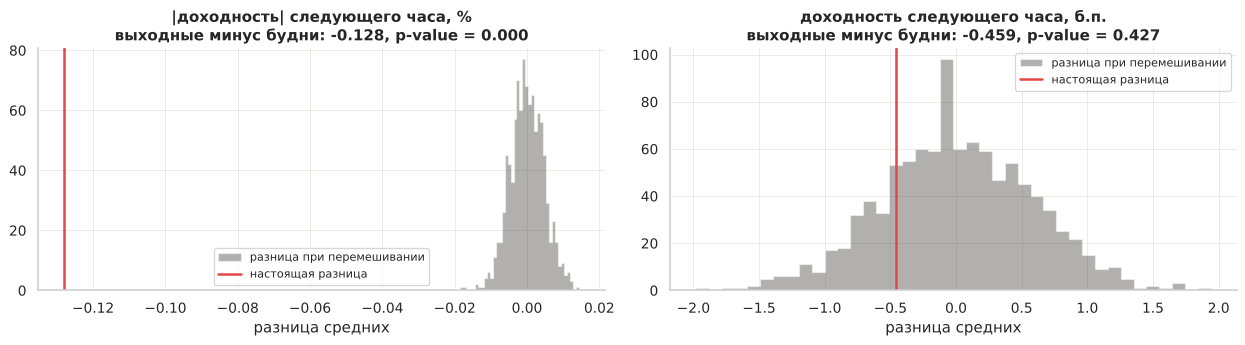

In [40]:
def permutation_test(values, groups, n_iter=1000, seed=0):
    # Разница средних между группами: наблюдаемая и при случайном перемешивании
    rng = np.random.default_rng(seed)
    mask = values.notna()
    values, groups = values[mask].to_numpy(), groups[mask].to_numpy()

    def diff(g):
        return values[g].mean() - values[~g].mean()

    observed = diff(groups)
    shuffled = np.array([diff(rng.permutation(groups)) for _ in range(n_iter)])
    p_value = (np.abs(shuffled) >= abs(observed)).mean()
    return observed, shuffled, p_value


fig, axes = plt.subplots(1, 2, figsize=(14, 4))
tests = [('target_abs', 100, '|доходность| следующего часа, %'), ('target', 10_000, 'доходность следующего часа, б.п.')]
for ax, (col, scale, label) in zip(axes, tests):
    observed, shuffled, p_value = permutation_test(df[col], df['is_weekend'])
    ax.hist(shuffled * scale, bins=40, color=GRAY, alpha=0.45, histtype='stepfilled', label='разница при перемешивании')
    ax.axvline(observed * scale, color=RED, linewidth=2, label='настоящая разница')
    ax.set_title(f'{label}\nвыходные минус будни: {observed * scale:+.3f}, p-value = {p_value:.3f}')
    ax.set_xlabel('разница средних')
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

Что видно:

* размер движения: в выходные 0.30%, в будни 0.43%. Ни одна из 1000 перестановок не дала такой разницы, значит она не случайна;
* доходность: разница −0.46 б.п., p-value 0.43. Такая разница легко получается случайно.

Календарь помогает понять, насколько сильно будет двигаться цена, но не куда.

# 11. Связь признаков с целевой переменной

## 11.1. Корреляции с таргетом

Считаем две корреляции, как на лекции: **Пирсона** (линейная связь) и **Спирмена** (монотонная связь, считается по рангам и не боится выбросов). Смотрим на связь каждого признака с доходностью следующего часа (`target`) и с размером движения (`target_abs`).

In [41]:
corr_table = pd.DataFrame({
    'target, Пирсон': df[feature_cols].corrwith(df['target']),
    'target, Спирмен': df[feature_cols].corrwith(df['target'], method='spearman'),
    'target_abs, Пирсон': df[feature_cols].corrwith(df['target_abs']),
    'target_abs, Спирмен': df[feature_cols].corrwith(df['target_abs'], method='spearman'),
})
corr_table.round(3)

,"target, Пирсон","target, Спирмен","target_abs, Пирсон","target_abs, Спирмен"
ret,-0.0210,-0.0570,-0.0360,-0.0220
ret_24h,-0.0100,-0.0340,-0.1020,-0.0270
range,0.0250,0.0190,0.3860,0.4010
vol_24h,0.0100,0.0130,0.3860,0.3660
log_volume,0.0010,0.0060,0.2460,0.2820
log_fut_volume,-0.0000,0.0060,0.2180,0.2830
volume_rel,0.0080,0.0100,0.1730,0.2230
fut_volume_rel,0.0040,0.0110,0.1660,0.2350
fut_spot_ratio,-0.0020,-0.0030,-0.0470,-0.0230
basis_bp,-0.0240,0.0070,0.0570,0.1040


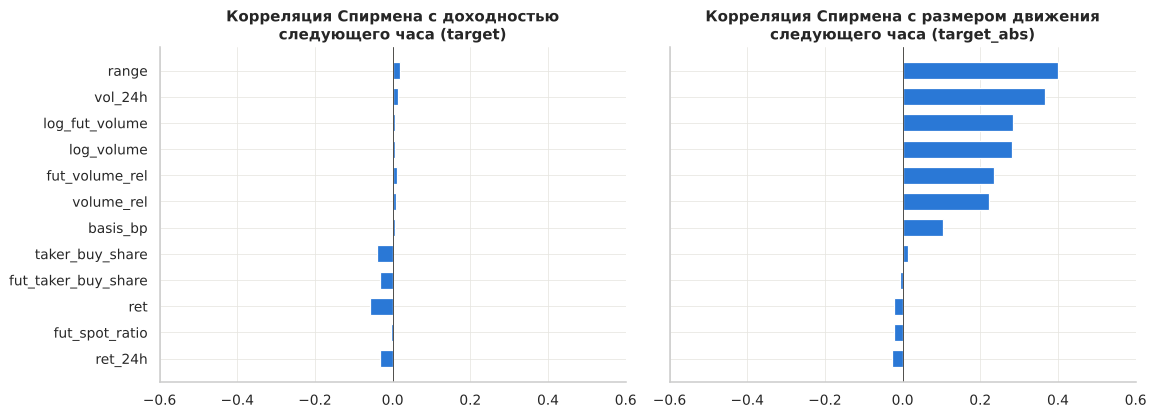

In [42]:
order = corr_table['target_abs, Спирмен'].sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True, sharex=True)
axes[0].barh(order, corr_table.loc[order, 'target, Спирмен'], color=BLUE, height=0.65)
axes[0].set_title('Корреляция Спирмена с доходностью\nследующего часа (target)')
axes[1].barh(order, corr_table.loc[order, 'target_abs, Спирмен'], color=BLUE, height=0.65)
axes[1].set_title('Корреляция Спирмена с размером движения\nследующего часа (target_abs)')
for ax in axes:
    ax.axvline(0, color=GRAY, linewidth=0.8)
    ax.set_xlim(-0.6, 0.6)
plt.tight_layout()
plt.show()

Что видно:

* с доходностью следующего часа почти ничего не коррелирует: максимум по модулю −0.057 (`ret`, Спирмен);
* с размером движения связь заметная: `range` 0.40, `vol_24h` 0.37, обороты 0.28.

Признаки объясняют размер движения, но не направление.

## 11.2. Попарные корреляции признаков

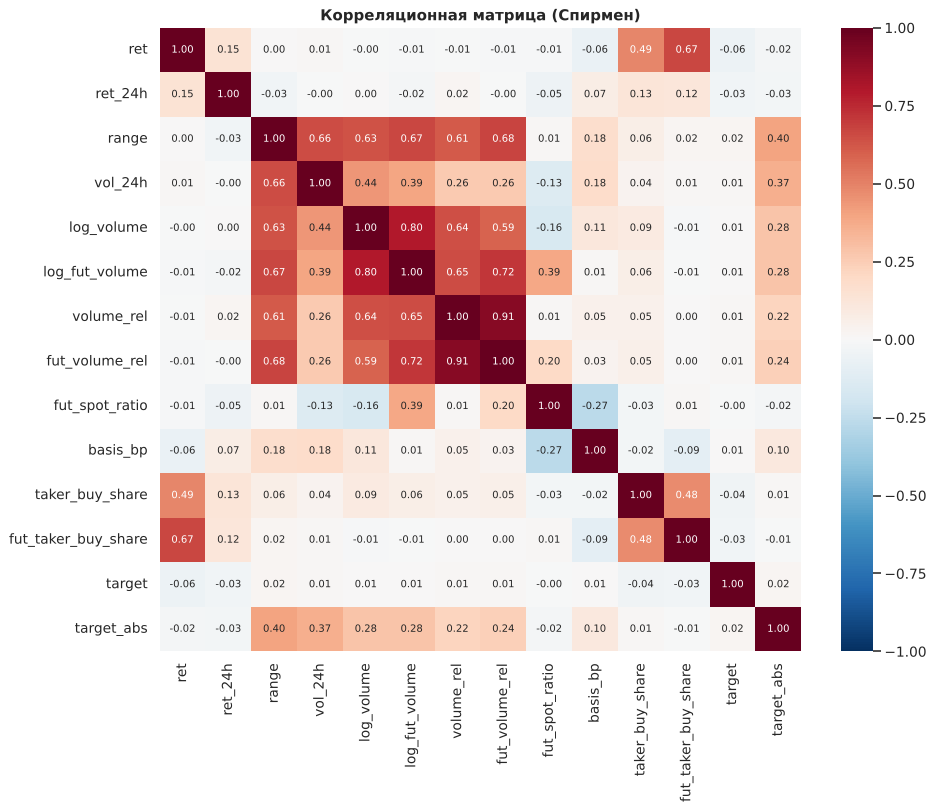

In [43]:
corr_cols = feature_cols + ['target', 'target_abs']
corr = df[corr_cols].corr(method='spearman')

plt.figure(figsize=(11.5, 9))
sns.heatmap(corr, cmap='RdBu_r', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', annot_kws={'size': 8})
plt.title('Корреляционная матрица (Спирмен)')
plt.show()

Многие признаки сильно связаны между собой:

* обороты спота и фьючерса: 0.80 для логарифмов и 0.91 для относительных;
* `range` с оборотами (0.61–0.68) и с `vol_24h` (0.66);
* `ret` с долей покупок тейкеров (0.49 и 0.67). Но это связь внутри одного часа, для прогноза она не помогает.

Для линейной регрессии это мультиколлинеарность: из похожих признаков нужно оставлять один.

## 11.3. Попарные распределения (pairplot)

Перед тем как верить коэффициенту корреляции, полезно посмотреть на точки (вспомним квартет Энскомба с лекции). Берём самые значимые признаки и случайную выборку в 3000 часов, чтобы график читался. Цвет — направление движения в следующем часе. Для наглядности крайние 0.5% значений каждого признака с каждой стороны на график не попадают.

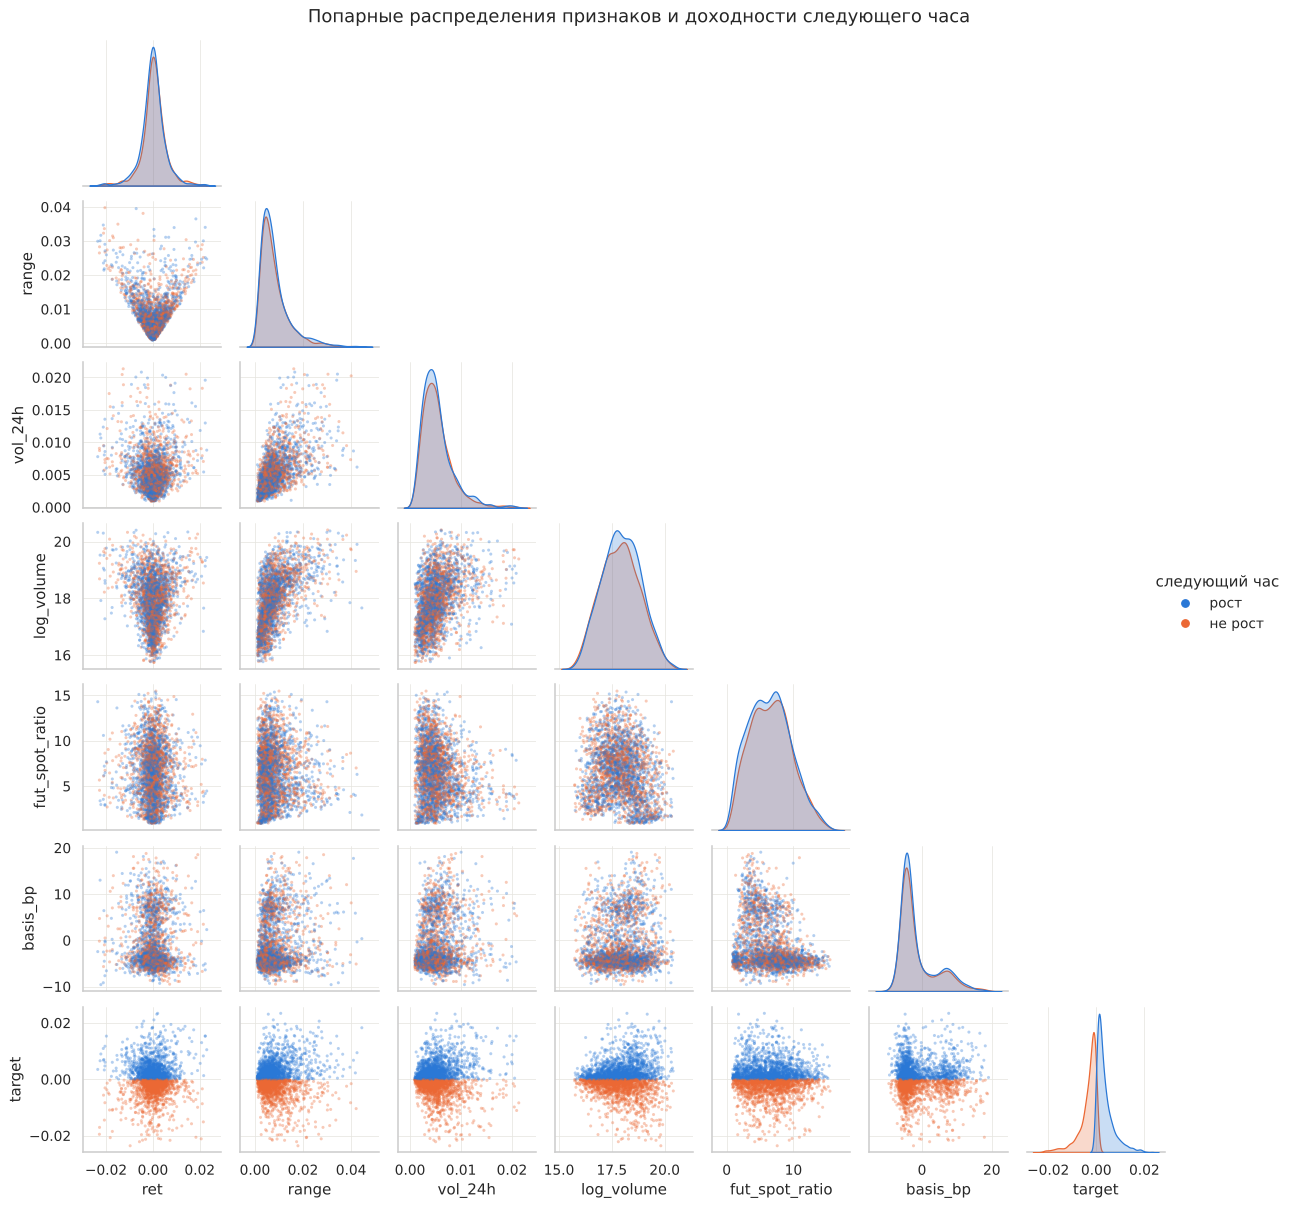

In [44]:
pair_cols = ['ret', 'range', 'vol_24h', 'log_volume', 'fut_spot_ratio', 'basis_bp', 'target']

sample = df[pair_cols + ['target_dir']].dropna().sample(3000, random_state=42)
for col in pair_cols:
    inside = sample[col].between(sample[col].quantile(0.005), sample[col].quantile(0.995))
    sample[col] = sample[col].where(inside)      # крайние значения не рисуем

grid = sns.pairplot(sample, vars=pair_cols, hue='target_dir', hue_order=['рост', 'не рост'],
                    palette=[BLUE, ORANGE], corner=True, height=1.9,
                    plot_kws={'s': 6, 'alpha': 0.35, 'linewidth': 0}, diag_kws={'linewidth': 1})
grid.figure.suptitle('Попарные распределения признаков и доходности следующего часа', y=1.01)

# своя легенда: в стандартной маркеры полупрозрачные и плохо видны
grid._legend.remove()
grid.figure.legend(handles=[Line2D([], [], marker='o', linestyle='', color=BLUE, label='рост'),
                         Line2D([], [], marker='o', linestyle='', color=ORANGE, label='не рост')],
                title='следующий час', loc='center right', frameon=False)
plt.show()

Что видно:

* `ret` и `range` образуют букву V: связь есть, но нелинейная, поэтому корреляция 0.00;
* `range`, `vol_24h` и `log_volume` растут вместе;
* у `basis_bp` два горба: около −4.5 и около +5…+10 б.п.;
* синие и оранжевые точки перемешаны: ни один признак не отделяет рост от не роста. В нижнем ряду цвета разделены только потому, что цвет посчитан из `target`.

## 11.4. Признаки по группам (когортам)

Корреляция — одно число, оно может спрятать нелинейную связь. Поэтому, как с `tenure` на лекции, разобьём каждый признак на 10 равных групп и посмотрим на среднее значение таргета в каждой. Вертикальные отрезки — 95% доверительный интервал среднего: если он пересекает пунктир (среднее по всем часам), отличие группы от среднего неотличимо от шума.

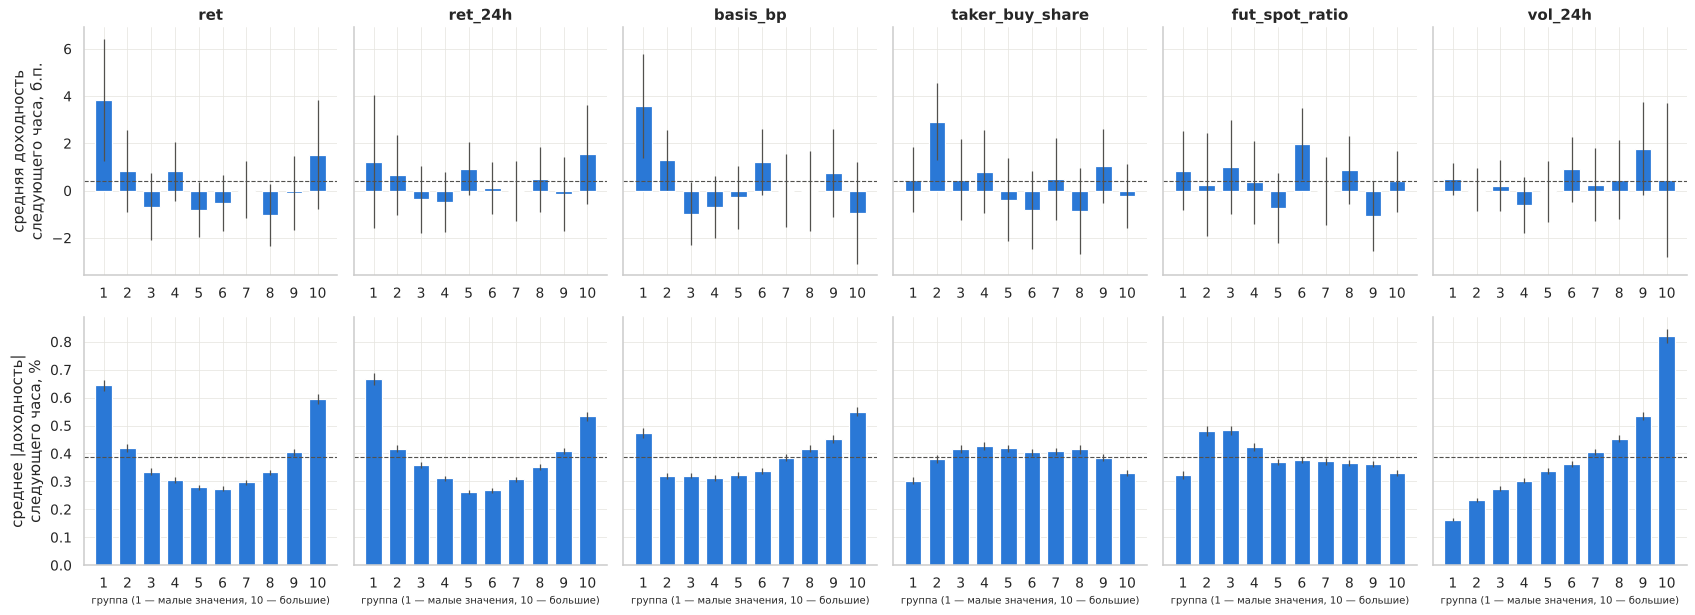

In [45]:
cohort_cols = ['ret', 'ret_24h', 'basis_bp', 'taker_buy_share', 'fut_spot_ratio', 'vol_24h']

fig, axes = plt.subplots(2, len(cohort_cols), figsize=(19, 7), sharey='row')
for j, col in enumerate(cohort_cols):
    groups = pd.qcut(df[col], 10, labels=range(1, 11))
    for i, (target_col, scale) in enumerate([('target', 10_000), ('target_abs', 100)]):
        stat = df.groupby(groups, observed=True)[target_col].agg(['mean', 'sem']) * scale
        ax = axes[i, j]
        ax.bar(stat.index.astype(str), stat['mean'], color=BLUE, width=0.7)
        ax.errorbar(stat.index.astype(str), stat['mean'], yerr=1.96 * stat['sem'],
                    fmt='none', ecolor=GRAY, elinewidth=1)
        ax.axhline(df[target_col].mean() * scale, color=GRAY, linestyle='--', linewidth=0.9)
        if i == 0:
            ax.set_title(col)
        else:
            ax.set_xlabel('группа (1 — малые значения, 10 — большие)', fontsize=8)
axes[0, 0].set_ylabel('средняя доходность\nследующего часа, б.п.')
axes[1, 0].set_ylabel('среднее |доходность|\nследующего часа, %')
plt.tight_layout()
plt.show()

Что видно:

* верхний ряд (направление): почти везде отличия от среднего в пределах погрешности. Исключения — после самых сильных падений (+3.8 б.п.) и при самом низком базисе (+3.5 б.п.), но это меньше комиссии за сделку;
* нижний ряд (размер движения): у `ret` и `ret_24h` получается буква U. И после сильного падения, и после сильного роста следующее движение крупнее: 0.53–0.67% против 0.26–0.28% в середине;
* у `vol_24h` размер движения растёт от 0.16% до 0.82%.

Связи с размером движения есть, но они нелинейные, поэтому корреляция их не показала.

# 12. Связь с объёмом фьючерсов

## 12.1. Фьючерс и спот: кто больше и как это менялось

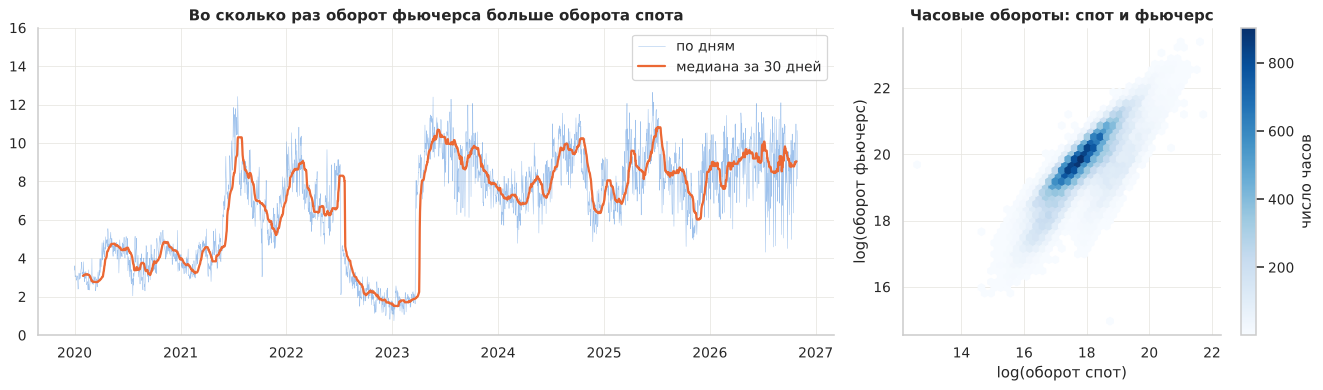

Корреляция log-оборотов спота и фьючерса: 0.818
Корреляция относительных оборотов (к своей медиане за 7 дней): 0.913 (Спирмен)

Отношение оборотов фьючерс / спот по годам:
year
2020   3.9800
2021   5.5500
2022   3.9000
2023   4.5600
2024   7.6700
2025   7.9700
2026   8.8000


In [46]:
daily = df[['quote_volume', 'fut_quote_volume']].resample('D').sum(min_count=1)
daily_ratio = daily['fut_quote_volume'] / daily['quote_volume']

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [2, 1]})

axes[0].plot(daily_ratio.index, daily_ratio, color=BLUE, linewidth=0.4, alpha=0.45, label='по дням')
axes[0].plot(daily_ratio.index, daily_ratio.rolling(30).median(), color=ORANGE, linewidth=1.8, label='медиана за 30 дней')
axes[0].set_ylim(0, 16)
axes[0].set_title('Во сколько раз оборот фьючерса больше оборота спота')
axes[0].legend()

hb = axes[1].hexbin(df['log_volume'], df['log_fut_volume'], gridsize=45, cmap='Blues', mincnt=1)
axes[1].set_xlabel('log(оборот спот)')
axes[1].set_ylabel('log(оборот фьючерс)')
axes[1].set_title('Часовые обороты: спот и фьючерс')
fig.colorbar(hb, ax=axes[1], label='число часов')

plt.tight_layout()
plt.show()

print(f"Корреляция log-оборотов спота и фьючерса: {df['log_volume'].corr(df['log_fut_volume']):.3f}")
print(f"Корреляция относительных оборотов (к своей медиане за 7 дней): {df['volume_rel'].corr(df['fut_volume_rel'], method='spearman'):.3f} (Спирмен)")
print('\nОтношение оборотов фьючерс / спот по годам:')
yearly = df.groupby('year')[['quote_volume', 'fut_quote_volume']].sum()
print((yearly['fut_quote_volume'] / yearly['quote_volume']).round(2).to_string())

Что видно:

* оборот фьючерса больше спотового в 4–9 раз: 3.98 в 2020 году, 8.80 в 2026;
* с середины 2022 до марта 2023 отношение падает до 2, а потом резко растёт до 10. Это тот же период нулевой комиссии на споте;
* обороты спота и фьючерса движутся вместе: корреляция 0.82 для логарифмов и 0.91 для относительных оборотов.

Объёмы спота и фьючерса во многом дублируют друг друга.

## 12.2. Объём фьючерса и будущие движения цены

Вопрос: помогает ли объём фьючерса предсказать, что будет дальше? Считаем корреляцию между относительным объёмом в час $t$ и размером движения цены в час $t+k$. При $k > 0$ объём **опережает** движение (это то, что нужно для прогноза), при $k < 0$ — запаздывает. Для сравнения то же самое для объёма спота.

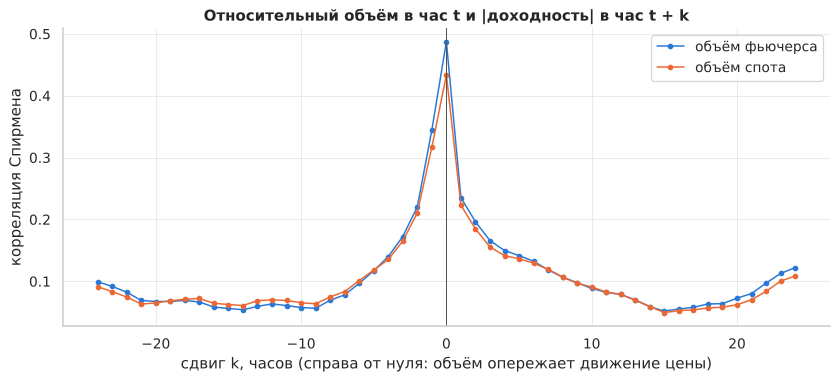

,-3,-2,-1,0,1,2,3,6,12,24
объём фьючерса,0.1720,0.2200,0.3450,0.4870,0.2350,0.1960,0.1660,0.1320,0.0790,0.1220
объём спота,0.1650,0.2110,0.3170,0.4340,0.2230,0.1850,0.1550,0.1290,0.0790,0.1090


In [47]:
shifts = range(-24, 25)
log_fut_rel = np.log(df['fut_volume_rel'].where(df['fut_volume_rel'] > 0))
log_spot_rel = np.log(df['volume_rel'].where(df['volume_rel'] > 0))

lead_lag = pd.DataFrame({
    'объём фьючерса': [log_fut_rel.corr(df['abs_ret'].shift(-k), method='spearman') for k in shifts],
    'объём спота': [log_spot_rel.corr(df['abs_ret'].shift(-k), method='spearman') for k in shifts],
}, index=shifts)

fig, ax = plt.subplots(figsize=(11, 4.3))
ax.plot(lead_lag.index, lead_lag['объём фьючерса'], color=BLUE, marker='o', markersize=3.5, label='объём фьючерса')
ax.plot(lead_lag.index, lead_lag['объём спота'], color=ORANGE, marker='o', markersize=3.5, label='объём спота')
ax.axvline(0, color=GRAY, linewidth=0.8)
ax.set_xlabel('сдвиг k, часов (справа от нуля: объём опережает движение цены)')
ax.set_ylabel('корреляция Спирмена')
ax.set_title('Относительный объём в час t и |доходность| в час t + k')
ax.legend()
plt.show()

lead_lag.loc[[-3, -2, -1, 0, 1, 2, 3, 6, 12, 24]].round(3).T

Теперь тот же вопрос в лоб, с оценкой уверенности через **бутстрэп** (как на лекции). Сравним часы, когда объём фьючерса был в верхних 10%, со всеми остальными: какое движение цены было в следующем часе?

In [48]:
high_fut_volume = df['fut_volume_rel'] > df['fut_volume_rel'].quantile(0.9)
valid = df['target'].notna() & df['fut_volume_rel'].notna()

rng = np.random.default_rng(0)
rows = []
for label, mask in [('объём фьючерса в верхних 10%', high_fut_volume & valid), ('остальные часы', ~high_fut_volume & valid)]:
    group = df.loc[mask]
    for col, scale, name in [('target_abs', 100, '|доходность| след. часа, %'),
                             ('target', 10_000, 'доходность след. часа, б.п.')]:
        values = group[col].to_numpy()
        boot = [rng.choice(values, size=len(values)).mean() for _ in range(1000)]
        low_b, high_b = np.percentile(boot, [2.5, 97.5])
        rows.append({'группа': label, 'показатель': name, 'часов': len(values),
                     'среднее': values.mean() * scale, 'нижняя граница': low_b * scale, 'верхняя граница': high_b * scale})

pd.DataFrame(rows).set_index(['показатель', 'группа']).sort_index().round(3)

часов  среднее  нижняя граница  верхняя граница
показатель                  группа                                                                       
|доходность| след. часа, %  объём фьючерса в верхних 10%   5964   0.5950          0.5770           0.6140
                            остальные часы                53677   0.3660          0.3620           0.3700
доходность след. часа, б.п. объём фьючерса в верхних 10%   5964   2.0190         -0.3240           4.3200
                            остальные часы                53677   0.2030         -0.3280           0.7240

Что видно:

* сильнее всего объём связан с движением цены в тот же час: 0.49 для фьючерса, 0.43 для спота;
* связь с будущим тоже есть: 0.24 на следующий час, 0.12 через сутки;
* объём фьючерса чуть информативнее спотового;
* после часов с объёмом фьючерса в верхних 10% следующее движение в среднем 0.60% против 0.37% в остальные часы, интервалы не пересекаются;
* для направления интервалы пересекаются и включают ноль.

Объём фьючерса помогает предсказать размер движения, но не направление.

## 12.3. Базис: разница цен фьючерса и спота

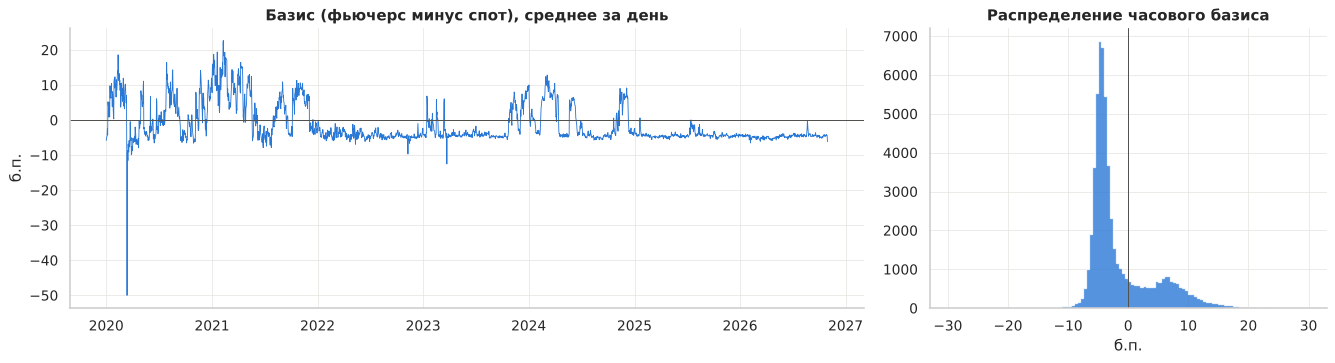

Средний базис по годам, б.п.:
        mean  median    std
year                       
2020  1.3300  0.5100 8.3900
2021  4.4900  4.7100 7.6500
2022 -4.3300 -4.4200 1.8600
2023 -2.3800 -3.8400 4.3500
2024 -0.2800 -2.7600 5.2400
2025 -4.3200 -4.4200 1.2100
2026 -4.6900 -4.7000 1.0200


In [49]:
daily_basis = df['basis_bp'].resample('D').mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [2, 1]})
axes[0].plot(daily_basis.index, daily_basis, color=BLUE, linewidth=0.7)
axes[0].axhline(0, color=GRAY, linewidth=0.8)
axes[0].set_ylabel('б.п.')
axes[0].set_title('Базис (фьючерс минус спот), среднее за день')

axes[1].hist(df['basis_bp'].dropna(), bins=120, range=(-30, 30), color=BLUE, alpha=0.8, histtype='stepfilled')
axes[1].axvline(0, color=GRAY, linewidth=0.8)
axes[1].set_xlabel('б.п.')
axes[1].set_title('Распределение часового базиса')
plt.tight_layout()
plt.show()

print('Средний базис по годам, б.п.:')
print(df.groupby('year')['basis_bp'].agg(['mean', 'median', 'std']).round(2).to_string())

Что видно:

* базис маленький, обычно в пределах ±10 б.п.;
* есть два режима: на растущем рынке фьючерс дороже спота на 5–20 б.п., в остальное время дешевле на 4–5 б.п.;
* в 2025–2026 годах базис почти не меняется (стандартное отклонение около 1 б.п.).

Почему в спокойные периоды фьючерс стабильно дешевле спота, мы не выясняли.

# 13. Сравнение BTC, ETH и SOL

Короткий раздел о том, насколько активы движутся вместе. Это важно для проекта: если альткоины повторяют BTC, отдельная модель для каждого даст мало новой информации, зато BTC можно использовать как признак.

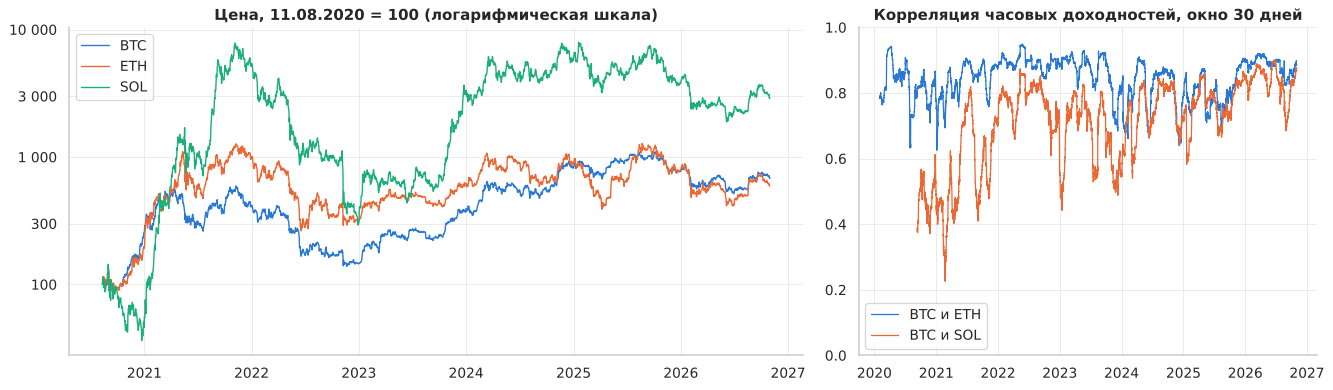

In [50]:
closes = pd.DataFrame({
    'BTC': df['close'],
    'ETH': eth.set_index('open_time')['close'].reindex(full_index).ffill(),
    'SOL': sol.set_index('open_time')['close'].reindex(full_index).ffill(),
})
asset_ret = np.log(closes).diff()

common_start = closes['SOL'].first_valid_index()
indexed = closes.loc[common_start:].resample('D').last()
indexed = indexed / indexed.iloc[0] * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1.6, 1]})
for col, color in zip(['BTC', 'ETH', 'SOL'], [BLUE, ORANGE, AQUA]):
    axes[0].plot(indexed.index, indexed[col], color=color, linewidth=1.1, label=col)
axes[0].set_yscale('log')
axes[0].set_yticks([100, 300, 1_000, 3_000, 10_000])
axes[0].set_yticklabels(['100', '300', '1 000', '3 000', '10 000'])
axes[0].set_title(f'Цена, {common_start:%d.%m.%Y} = 100 (логарифмическая шкала)')
axes[0].legend()

rolling_corr = pd.DataFrame({
    'BTC и ETH': asset_ret['BTC'].rolling(720).corr(asset_ret['ETH']),
    'BTC и SOL': asset_ret['BTC'].rolling(720).corr(asset_ret['SOL']),
})
axes[1].plot(rolling_corr.index, rolling_corr['BTC и ETH'], color=BLUE, linewidth=1, label='BTC и ETH')
axes[1].plot(rolling_corr.index, rolling_corr['BTC и SOL'], color=ORANGE, linewidth=1, label='BTC и SOL')
axes[1].set_ylim(0, 1)
axes[1].set_title('Корреляция часовых доходностей, окно 30 дней')
axes[1].legend()
plt.tight_layout()
plt.show()

In [51]:
print('Корреляция часовых доходностей (Пирсон), общий период с', f'{common_start:%d.%m.%Y}')
display(asset_ret.loc[common_start:].corr().round(3))

summary = pd.DataFrame({
    'волатильность, % годовых': asset_ret.loc[common_start:].std() * annualize,
    'эксцесс': asset_ret.loc[common_start:].kurt(),
    'рост цены за период, раз': closes.iloc[-1] / closes.loc[common_start],
})
display(summary.round(2))

print('Опережает ли BTC альткоины? Корреляция доходности BTC в час t с доходностью актива в час t + 1:')
print(asset_ret.loc[common_start:].shift(-1).corrwith(asset_ret.loc[common_start:, 'BTC']).round(4).to_string())

Корреляция часовых доходностей (Пирсон), общий период с 11.08.2020


,BTC,ETH,SOL
BTC,1.0000,0.8380,0.6340
ETH,0.8380,1.0000,0.6700
SOL,0.6340,0.6700,1.0000


,"волатильность, % годовых",эксцесс,"рост цены за период, раз"
BTC,57.7400,16.1000,6.6000
ETH,75.9800,14.6700,5.7600
SOL,118.61,20.2500,32.3700


Опережает ли BTC альткоины? Корреляция доходности BTC в час t с доходностью актива в час t + 1:
BTC   -0.0082
ETH   -0.0006
SOL   -0.0186


Что видно:

* корреляция часовых доходностей BTC и ETH 0.84, BTC и SOL 0.63, со временем она растёт;
* альткоины волатильнее: 58% годовых у BTC, 76% у ETH, 119% у SOL;
* на часовом шаге BTC не опережает альткоины.

Начинаем с BTC, остальные активы подключаются тем же кодом.

# 14. Сохраняем очищенный датасет

Таблица с обработанными пропусками, флагами и признаками пригодится на следующем чекпойнте (простые модели).

In [52]:
os.makedirs('data', exist_ok=True)
out_path = 'data/btc_1h_dataset.csv.gz'
# сохраняем очищенные свечи, флаги и таргет; признаки пересчитываются кодом из раздела 3.2
save_cols = price_cols + flow_cols + [c for c in df.columns if c.startswith('fut_') and c in fut_i.columns] \
            + ['spot_halt', 'fut_missing', 'ret', 'target']
df[save_cols].to_csv(out_path, float_format='%.10g')
print(f'Сохранено: {out_path}, строк {len(df)}, колонок {len(save_cols)}, размер {os.path.getsize(out_path) / 1e6:.1f} МБ')

Сохранено: data/btc_1h_dataset.csv.gz, строк 59904, колонок 22, размер 5.6 МБ


# 15. Выводы

## Данные

* Binance, BTCUSDT спот и бессрочный фьючерс, шаг 1 час, 01.01.2020 – 31.10.2026, 59 904 часа.
* Дублей и ошибочных значений нет, OHLC корректен.
* Пропусков 0.05% в споте и 0.04% во фьючерсе. В споте это остановки торгов биржи, во фьючерсе — сутки, которых нет в архиве.
* Часы остановки спота заполнили последней ценой и нулевым объёмом, сутки по фьючерсу оставили пустыми. И то, и другое помечено флагами.
* Скачки цены настоящие (есть и на споте, и на фьючерсе), мы их не удаляем.

## Что узнали

1. Цена нестационарна, доходность стационарна. Прогнозировать нужно доходность.
2. Доходности не нормальные, с тяжёлыми хвостами.
3. Автокорреляции доходностей почти нет.
4. Волатильность кластеризуется и снижается от года к году: с 75–86% до 42–45% годовых.
5. У объёма и волатильности есть суточный и недельный ритм.
6. Фьючерсный рынок в 4–9 раз больше спотового. Объём фьючерса связан с размером будущего движения, но не с направлением.
7. BTC, ETH и SOL сильно связаны между собой.

Главное: по ценам и объёмам хорошо видно, насколько сильно сдвинется цена в следующем часе (корреляция до 0.40), и почти не видно, куда (не больше 0.06). Поэтому сигнал о направлении будем искать в новостях и текстах, как и задумано в проекте.

## Что делаем дальше

* **Целевая переменная**: лог-доходность следующего периода, сравним горизонты 1 час и 24 часа. Дополнительно попробуем предсказывать размер движения.
* **Бейзлайны**: «доходность равна нулю», «всегда рост» (50.7%), «движение как в прошлом часе».
* **Признаки**: лаги доходности и её модуля, волатильность за 24 часа, объём относительно медианы за 7 дней, час суток и день недели.
* **Предобработка**: логарифм объёмов и масштабирование. Все параметры считаем только на обучающей части.
* **Валидация**: разбиение по времени, без перемешивания.
* **Метрики**: MAE и MSE в сравнении с бейзлайном.

## Ограничения

* Данные одной биржи.
* Комиссии не учитываем.
* Сутки 28.10.2026 по фьючерсу нужно дозагрузить.